# Analyse de la Base de Données Installations des Produits CNI

## I. Exploration et Nettoyage des données :

## 1. Compréhension des données

### 1.1 Importation des librairies

In [146]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression, SelectKBest
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix,
                             mean_squared_error, mean_absolute_error, r2_score)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

import warnings
warnings.filterwarnings("ignore")

In [147]:
import matplotlib.pyplot as plt
import seaborn as sns

# Style général
sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 120,

    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,

    "axes.grid": True,
    "grid.alpha": 0.3,

    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})
sns.set_palette(["#6d6fd6"])

### 1.2 Chargement des données

In [148]:
df = pd.read_csv("installations_produits_CNI.csv", delimiter=";", encoding="cp1252")

### 1.3 Aperçu du dataset

* Premières observations :

In [149]:
df.head()

,Nom_produit,version_produit,date_installation,Gouvernorat,Id_Client,Type_client,Systeme_exploitation_poste,installation_reussie,nombre_essais_installation,client_a_reclame,nombre_reclamations_client,client_satisfait,Remarques,Technicien_ID,Duree_installation_minutes,Debit_reseau_Mbps,Taille_site_postes,Mode_installation,Tentative_installation_weekend,Version_precedente
0,INSAF,1.1,2019-02-24 00:00:00,Gafsa,CIN10000,Ministère,Windows 2012 Server,non,5,oui,2,non,problème réseau,TECH_038,139,"4,43",15,Technicien_sur_site,oui,1.0
1,INSAF,2.1,2021-02-13 00:00:00,Tunis,CIN10001,Ministère,Windows 2012 Server,non,5,oui,4,non,version incompatible,TECH_045,163,"35,34",21,Technicien_sur_site,oui,1.1
2,INSAF,3.0,2018-06-27 00:00:00,Kébili,CIN10002,Ministère,Win11,non,3,oui,2,non,Problème adressage ip,TECH_035,55,"97,37",17,Télémaintenance,oui,2.0
3,INSAF,3.0,2021-03-31 00:00:00,Ben Arous,CIN10003,EPA,Windows 2008 Server,oui,3,oui,0,non,erreur configuration poste,TECH_007,112,"29,24",9,Télémaintenance,oui,1.1
4,INSAF,2.2,2019-12-02 00:00:00,Sidi Bouzid,CIN10004,EPA,Windows 2012 Server,non,5,oui,5,non,erreur configuration poste,TECH_011,143,"39,19",7,Technicien_sur_site,non,0.9


* Forme du dataframe :

In [150]:
df.shape

(15272, 20)

On a 8200 lignes et 20 colonnes

* Types des données :

In [151]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15272 entries, 0 to 15271
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Nom_produit                     15272 non-null  str    
 1   version_produit                 15272 non-null  float64
 2   date_installation               15272 non-null  str    
 3   Gouvernorat                     15272 non-null  str    
 4   Id_Client                       15097 non-null  str    
 5   Type_client                     15272 non-null  str    
 6   Systeme_exploitation_poste      15272 non-null  str    
 7   installation_reussie            15175 non-null  str    
 8   nombre_essais_installation      15272 non-null  int64  
 9   client_a_reclame                15272 non-null  str    
 10  nombre_reclamations_client      15272 non-null  int64  
 11  client_satisfait                15272 non-null  str    
 12  Remarques                       8236 non-nu

Dans la table on a 4 variables de type entier(`int64`), une variable de type réel(`float64`) et 15 variables de type chaine de caractères(`object`)
On constate que :
- `date_installation` est de type `object` et on doit la changer en type `date_time`
- `Debit_reseau_Mbps` est de type `object` et on doit la changer en type `float64`
- `version_produit` est de type `float64`et on doit la changer en type `object`
- on doit encoder les variables `installation_reussie`, `client_a_reclame`, `client_satisfait` et `Tentative_installation_weekend` et `Mode_installation` (oui : 1 et non : 0)

* Duplication :

In [152]:
df.duplicated().sum()

np.int64(116)

Dans le csv il y a 123 lignes dupliquées

## 2. Nettoyage initial des données
Objectif : corriger les problèmes évidents avant l’analyse exploratoire.

    - on doit changer la colonne `date_installation` en type Date 
    - changer le `Debit_reseau_Mbps` en reel du type `float64`

### 2.1 Correction des types de données

In [153]:
df['date_installation'] = pd.to_datetime(df['date_installation'], errors='coerce')

In [154]:
df['Debit_reseau_Mbps'] = df['Debit_reseau_Mbps'].str.replace(",", ".").astype(float)

In [155]:
df['Version_precedente'] = df['Version_precedente'].str.replace('aucune','0')
df['Version_precedente'].value_counts()

Version_precedente
1.0    2578
0.9    2576
0      2568
1.1    2533
2.0    2523
1.2    2494
Name: count, dtype: int64

In [156]:
df['version_produit'] = df['version_produit'].astype(object)

In [157]:
# Pour vérifier les types de données après les conversions 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15272 entries, 0 to 15271
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   Nom_produit                     15272 non-null  str           
 1   version_produit                 15272 non-null  object        
 2   date_installation               15272 non-null  datetime64[us]
 3   Gouvernorat                     15272 non-null  str           
 4   Id_Client                       15097 non-null  str           
 5   Type_client                     15272 non-null  str           
 6   Systeme_exploitation_poste      15272 non-null  str           
 7   installation_reussie            15175 non-null  str           
 8   nombre_essais_installation      15272 non-null  int64         
 9   client_a_reclame                15272 non-null  str           
 10  nombre_reclamations_client      15272 non-null  int64         
 11  client_satisf

### 2.2 Suppression des doublons

In [158]:
df.drop_duplicates(inplace=True)

## 3. Analyse exploratoire des données (EDA)

### Analyse descriptive:
    Objectif : L’analyse descriptive a pour objectif d’expliquer ce qui s’est passé dans le passé. Elle se concentre sur l’analyse des données historiques afin d’identifier des tendances, des patterns et d’obtenir des résumés pertinents. Elle repose sur les statistiques descriptives, qui consistent à résumer et organiser les données pour décrire leurs principales caractéristiques. Cela inclut les mesures de tendance centrale (moyenne, médiane, mode), les mesures de dispersion (étendue, variance, écart-type) ainsi que les visualisations (histogrammes, diagrammes en barres, boîtes à moustaches). L’analyse descriptive permet ainsi de mieux comprendre la structure et l’aspect général des données.

### 3.1 Détection des valeurs manquantes

In [159]:
df.isna().sum()

Nom_produit                          0
version_produit                      0
date_installation                    0
Gouvernorat                          0
Id_Client                          174
Type_client                          0
Systeme_exploitation_poste           0
installation_reussie                97
nombre_essais_installation           0
client_a_reclame                     0
nombre_reclamations_client           0
client_satisfait                     0
Remarques                         6976
Technicien_ID                        0
Duree_installation_minutes           0
Debit_reseau_Mbps                    0
Taille_site_postes                   0
Mode_installation                    0
Tentative_installation_weekend       0
Version_precedente                   0
dtype: int64

Il y a troix variables qui ont des valeurs manquantes : `Id_Client`, `installation_reussie` et `Remarques`.

### 3.2 Détection des données inconsistante :

In [160]:
df['Systeme_exploitation_poste'].value_counts()

Systeme_exploitation_poste
Win10                  2343
Win11                  2310
Windows server 2022    1957
Windows server 2019    1939
Windows server 2016    1930
Win8                   1113
Windows 2012 Server    1104
Win7                   1103
Windows 2008 Server    1090
WindowsXP               101
win10                    60
Unknown                  56
Win 10                   50
Name: count, dtype: int64

- on constate qu'il existe un incoherence des donnes dans la colonne `Systeme_exploitation_poste` pour les valeurs `win10` et `Win 10` et `Win10`

- Il existe des postes avec des system d'exploitation  `Unknown`, et on doit faire une analyse

### 3.3 Detection des valeurs inhabituelles :

nombre_reclamations_client
 0     6772
 3     1696
 1     1693
 2     1663
 4     1663
 6      741
 5      732
 25     103
-2       93
Name: count, dtype: int64


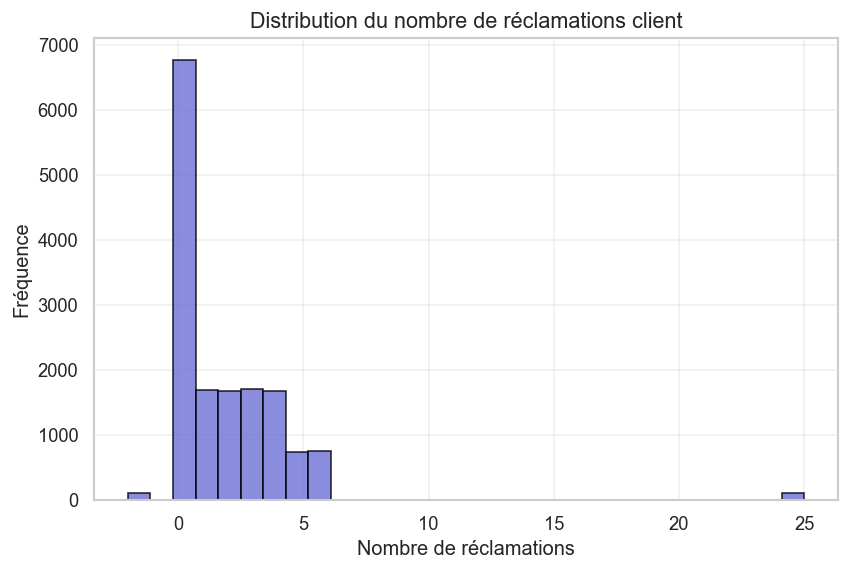

In [161]:
print(df['nombre_reclamations_client'].value_counts())
plt.figure(figsize=(8,5))
plt.hist(
    df['nombre_reclamations_client'], 
    bins=30,
    edgecolor='black',   
    alpha=0.8)
plt.title("Distribution du nombre de réclamations client")
plt.xlabel("Nombre de réclamations")
plt.ylabel("Fréquence")
plt.show()

Dans la colonne `nombre_reclamations_client`, des valeurs abherente ont été détectées, notamment  `-2` et `25` 
- la valeur `-2` est incohérente , car le nombre de reclamations ne peut pas etre negatif.
- la valeur  `25` semble anormalement élevée par rapport au reste des valeurs.

Version_precedente
1.0    2557
0.9    2553
0      2536
1.1    2518
2.0    2514
1.2    2478
Name: count, dtype: int64


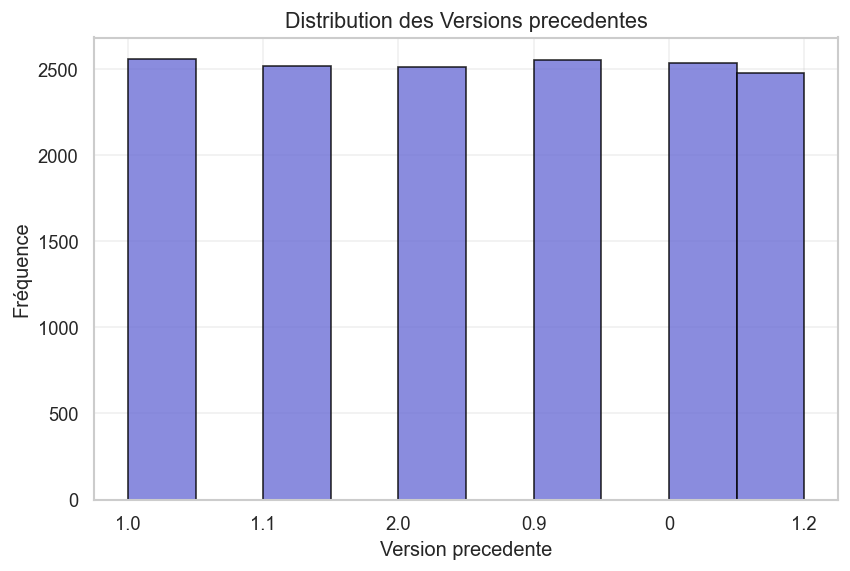

In [162]:
print(df['Version_precedente'].value_counts())
plt.figure(figsize=(8,5))
plt.hist(
    df['Version_precedente'],
    edgecolor='black',   
    alpha=0.8)
plt.title("Distribution des Versions precedentes")
plt.xlabel("Version precedente")
plt.ylabel("Fréquence")
plt.show()

On a 1311 clients qui n'ont pas de version précedente on va alors transformer aucune en 0

date_installation
2019    2028
2023    1962
2021    1949
2020    1940
2022    1937
2018    1912
2024    1845
2025    1502
2036      81
Name: count, dtype: int64


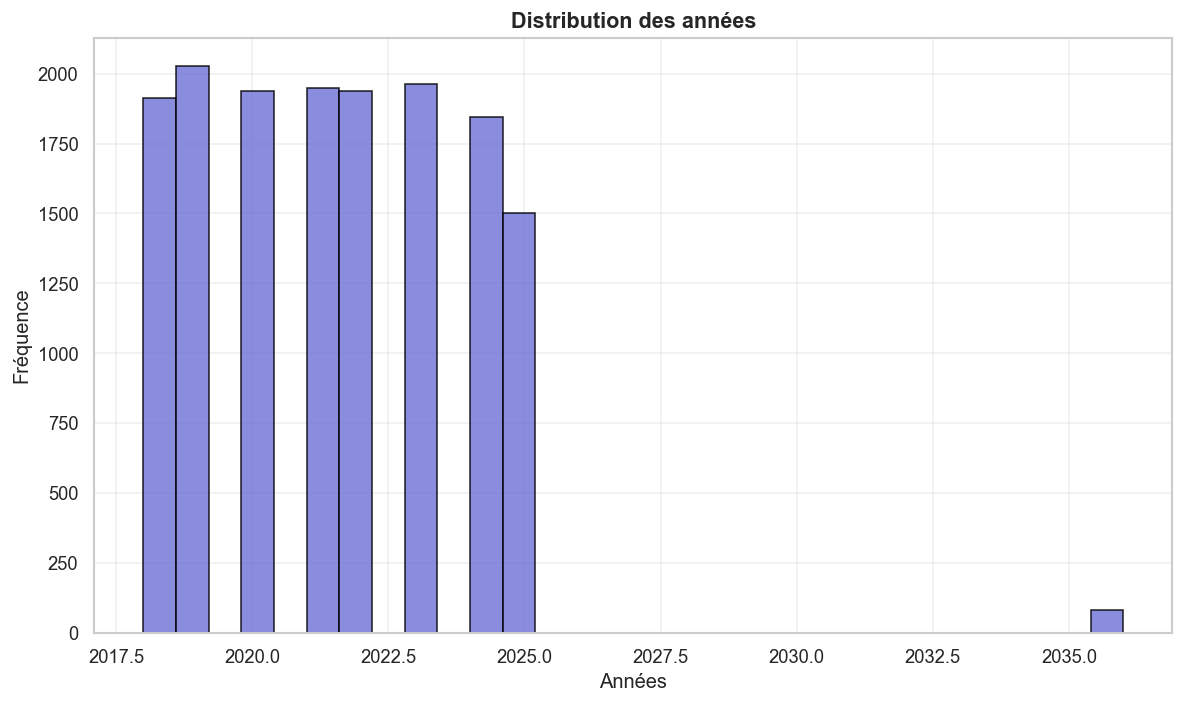

In [163]:
df['date_installation'] = pd.to_datetime(df['date_installation'], errors='coerce')
years = df['date_installation'].dt.year

print(years.value_counts())
plt.figure(figsize=(10,6))
plt.hist(
    years,
    bins=30,
    edgecolor='black',   
    alpha=0.8            
)
plt.title("Distribution des années", weight='bold')
plt.xlabel("Années")
plt.ylabel("Fréquence")
plt.tight_layout()
plt.show()

Remplacer les valeurs `aucune` dans la variable `Version_precedente`

### 3.4 Analyse statistique des variables qualitatives

In [164]:
df.describe()

,date_installation,nombre_essais_installation,nombre_reclamations_client,Duree_installation_minutes,Debit_reseau_Mbps,Taille_site_postes
count,15156,15156.000000,15156.000000,15156.000000,15156.000000,15156.000000
mean,2021-12-12 19:16:50.177553,3.551729,1.798232,95.094484,47.306274,13.102996
min,2018-01-01 00:00:00,1.000000,-2.000000,30.000000,0.010000,1.000000
25%,2019-12-03 00:00:00,2.000000,0.000000,57.000000,19.235000,6.000000
50%,2021-11-13 12:00:00,4.000000,1.000000,96.000000,47.165000,11.000000
75%,2023-10-27 00:00:00,5.000000,3.000000,130.000000,73.675000,20.000000
max,2036-12-22 07:45:29,5.000000,25.000000,202.000000,100.000000,30.000000
std,NaN,1.651858,2.705506,43.274221,30.144429,8.309202


d'après le tableau ci dessus on a les statistique suivantes:
- l'existence d'une date future dans la colonne `date_installation` ce qui est absurde 
- moyenne du `nombre_essais_installation` est de 2.98, qui est moyen par rapport au nombre d'essais qui varie entre 1 et 5
- moyenne du `nombre_reclamations_client` est de 2.83, le moyenne est proche de la mediane ce qui indique une ue distribution symetrique  on constate que `le coefficient de variation` est egale a 0.865 ce qui insique une dispersion forte des données donc possibilité d'avoir des valeurs aberrantes
- `Duree_installation_minutes` et `Debit_reseau_Mbps` il ya une possibilitées d'avoir des valeurs aberrantes dans ces deux variables du l'ecart important entre l'ecart-type et la distribution des données entre les quartiles.
- l’écart type (46.1)  de la variables `Duree_installation_minutes` indique que certaines installations sont beaucoup plus rapides ou lentes que la moyenne.

### 3.5 Analyse statistique des variables quantitatives

In [165]:
df.describe(include='object')

,Nom_produit,version_produit,Gouvernorat,Id_Client,Type_client,Systeme_exploitation_poste,installation_reussie,client_a_reclame,client_satisfait,Remarques,Technicien_ID,Mode_installation,Tentative_installation_weekend,Version_precedente
count,15156,15156.0,15156,14982,15156,15156,15059,15156,15156,8180,15156,15156,15156,15156
unique,4,7.0,24,12715,4,13,2,2,2,7,50,2,2,6
top,MAKATIB,1.0,Ariana,CMA10328,EPNA,Win10,non,oui,non,version incompatible,TECH_045,Technicien_sur_site,non,1.0
freq,3830,2299.0,691,4,3864,2343,7803,8974,8634,2893,337,7591,7715,2557


### 3.6 Covariance

In [166]:
df.describe(include='object')

,Nom_produit,version_produit,Gouvernorat,Id_Client,Type_client,Systeme_exploitation_poste,installation_reussie,client_a_reclame,client_satisfait,Remarques,Technicien_ID,Mode_installation,Tentative_installation_weekend,Version_precedente
count,15156,15156.0,15156,14982,15156,15156,15059,15156,15156,8180,15156,15156,15156,15156
unique,4,7.0,24,12715,4,13,2,2,2,7,50,2,2,6
top,MAKATIB,1.0,Ariana,CMA10328,EPNA,Win10,non,oui,non,version incompatible,TECH_045,Technicien_sur_site,non,1.0
freq,3830,2299.0,691,4,3864,2343,7803,8974,8634,2893,337,7591,7715,2557


In [167]:
df_num = df.select_dtypes(include=[np.number])
cov = df_num.cov()
cov

,nombre_essais_installation,nombre_reclamations_client,Duree_installation_minutes,Debit_reseau_Mbps,Taille_site_postes
nombre_essais_installation,2.728634,2.342540,51.928863,-17.825637,-3.129083
nombre_reclamations_client,2.342540,7.319762,49.029821,-17.281633,-2.829630
Duree_installation_minutes,51.928863,49.029821,1872.658179,-813.820509,2.302112
Debit_reseau_Mbps,-17.825637,-17.281633,-813.820509,908.686611,17.865570
Taille_site_postes,-3.129083,-2.829630,2.302112,17.865570,69.042839


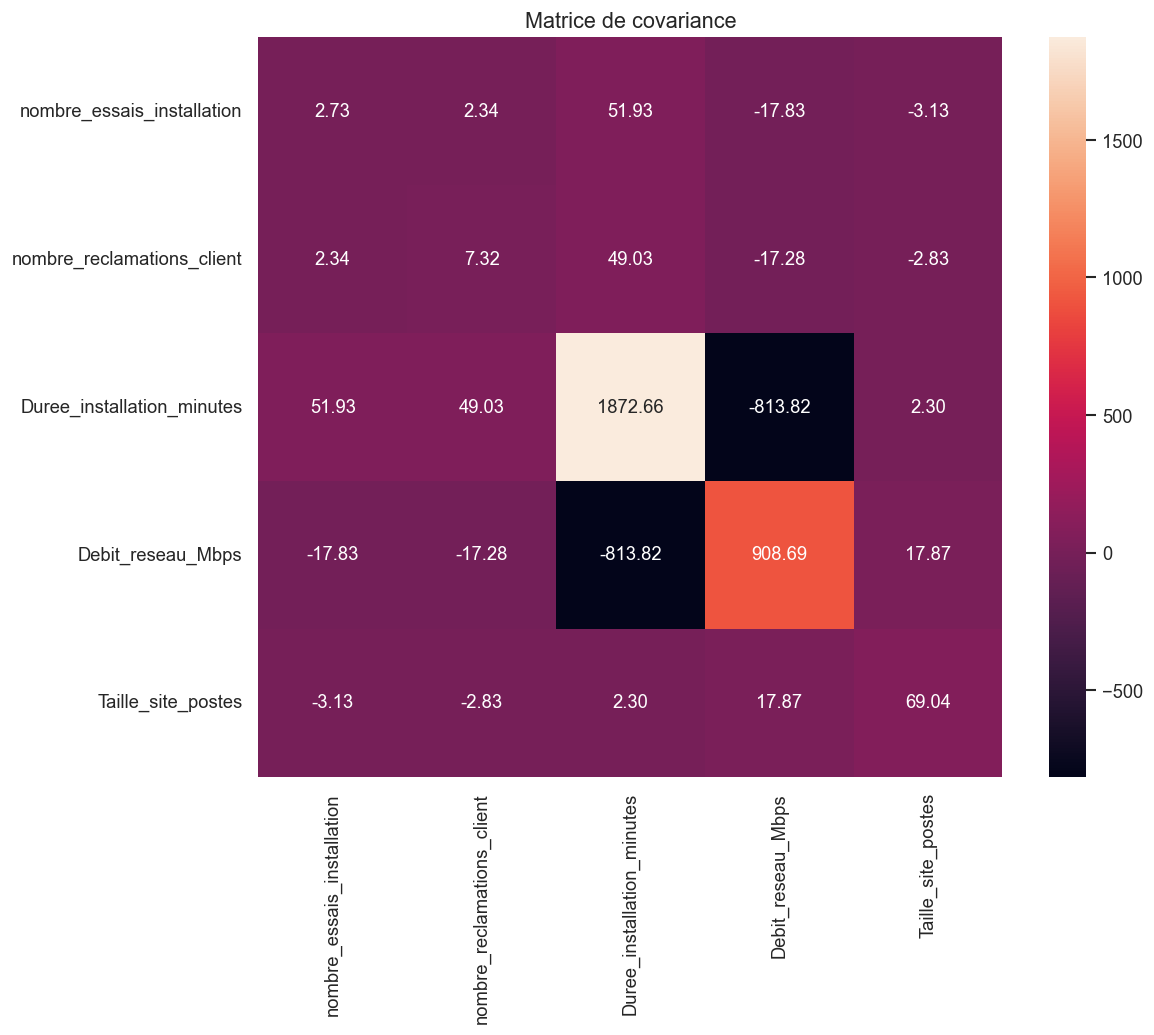

In [168]:
plt.figure(figsize=(10,8))
sns.heatmap(cov, annot=True, fmt=".2f")
plt.title("Matrice de covariance")
plt.show()

In [169]:
df.columns

Index(['Nom_produit', 'version_produit', 'date_installation', 'Gouvernorat',
       'Id_Client', 'Type_client', 'Systeme_exploitation_poste',
       'installation_reussie', 'nombre_essais_installation',
       'client_a_reclame', 'nombre_reclamations_client', 'client_satisfait',
       'Remarques', 'Technicien_ID', 'Duree_installation_minutes',
       'Debit_reseau_Mbps', 'Taille_site_postes', 'Mode_installation',
       'Tentative_installation_weekend', 'Version_precedente'],
      dtype='str')

### 3.7 Coefficient de corrélation

In [170]:
coeff_corr = df_num.corr(method='pearson')
coeff_corr

,nombre_essais_installation,nombre_reclamations_client,Duree_installation_minutes,Debit_reseau_Mbps,Taille_site_postes
nombre_essais_installation,1.000000,0.524162,0.726452,-0.357985,-0.227974
nombre_reclamations_client,0.524162,1.000000,0.418777,-0.211899,-0.125870
Duree_installation_minutes,0.726452,0.418777,1.000000,-0.623867,0.006402
Debit_reseau_Mbps,-0.357985,-0.211899,-0.623867,1.000000,0.071326
Taille_site_postes,-0.227974,-0.125870,0.006402,0.071326,1.000000


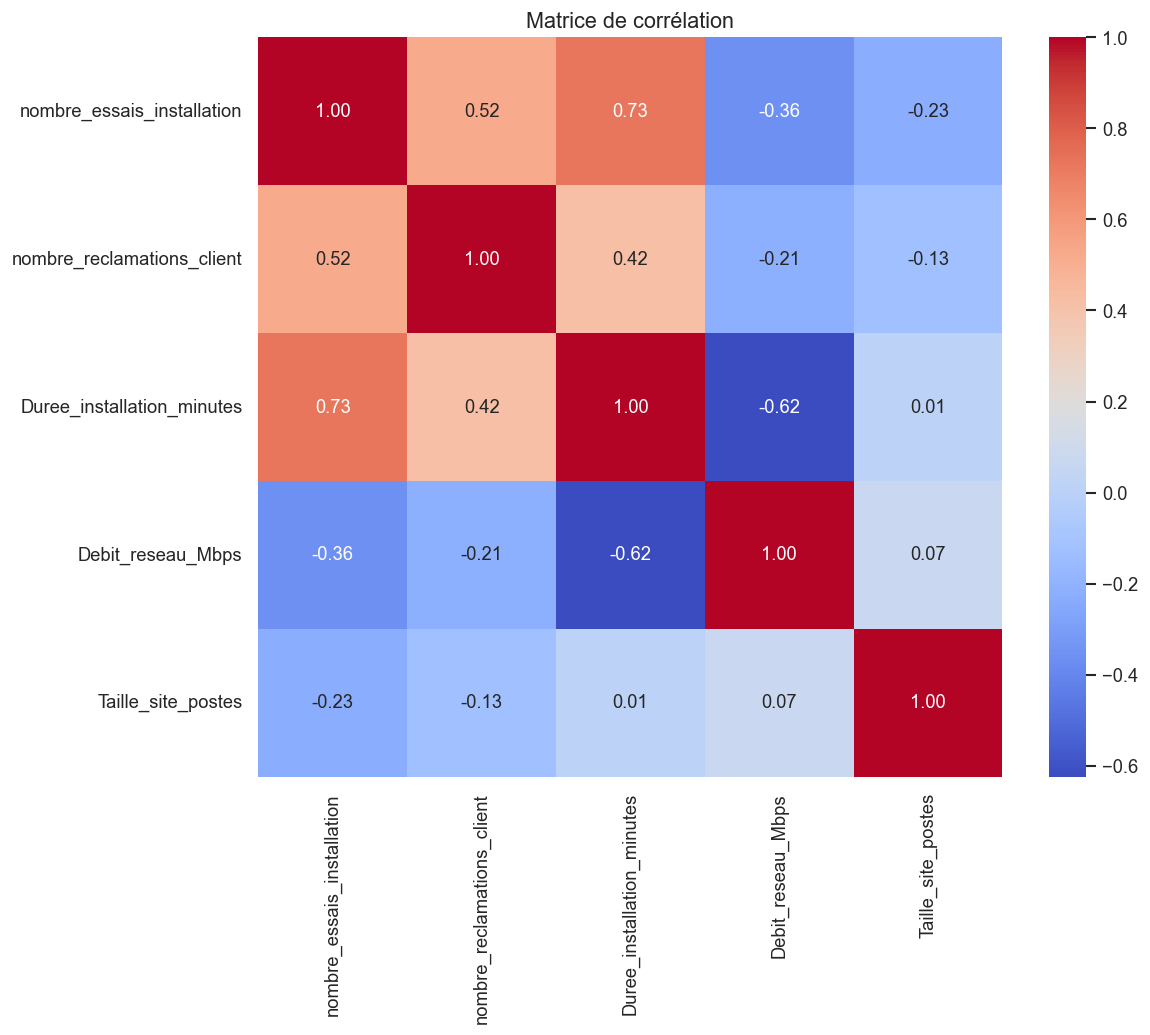

In [171]:
plt.figure(figsize=(10,8))
sns.heatmap(coeff_corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matrice de corrélation")
plt.show()

### 3.6 Detection des Valeurs Aberrantes :

> *méthode 1* : visualisation

<Axes: xlabel='nombre_reclamations_client'>

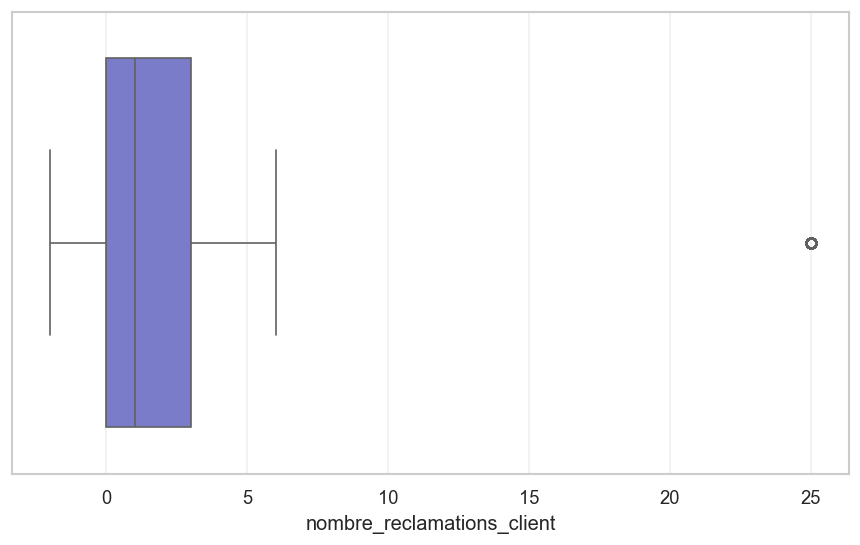

In [172]:
sns.boxplot(x=df['nombre_reclamations_client']) 

> *méthode 2* : IQR

In [173]:
Q1 = df['nombre_reclamations_client'].quantile(0.25)
Q3 = df['nombre_reclamations_client'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[(df['nombre_reclamations_client'] > lower) & (df['nombre_reclamations_client'] < upper)]

print(Q1, Q3, IQR)


0.0 3.0 3.0


la methode d'interquartile ne détecte pas les valeurs négatives proches comme -2 car la marge de confiance est [-3.5,8.5] qui est une valeur abherente comme `nombre_reclamations_client` ne peut pas etre négatif , donc il  faut supprimer cette valeur et la valeur 25 detecter par IQR.

<Axes: xlabel='Debit_reseau_Mbps'>

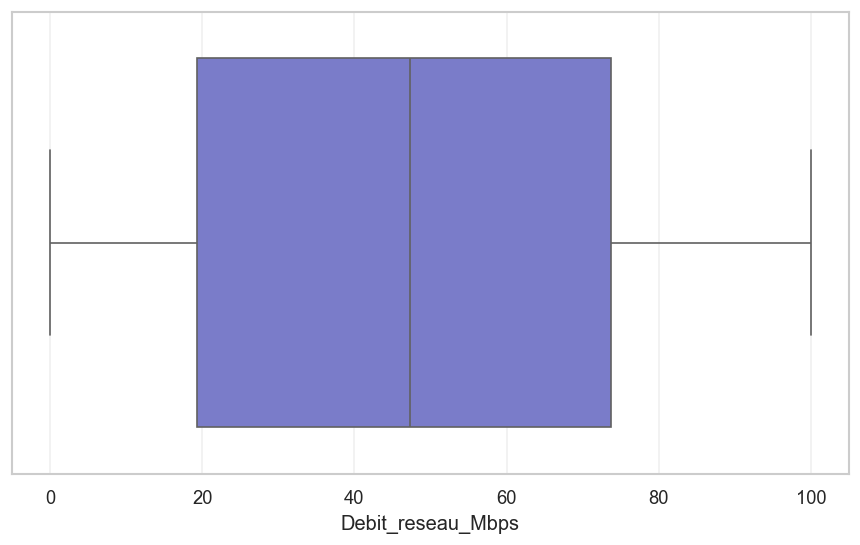

In [174]:
sns.boxplot(x=df['Debit_reseau_Mbps']) 

In [175]:
Q1 = df['Debit_reseau_Mbps'].quantile(0.25)
Q3 = df['Debit_reseau_Mbps'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['Debit_reseau_Mbps'] < Q1 - 1.5 * IQR) | (df['Debit_reseau_Mbps'] > Q3 + 1.5 * IQR)]
print(outliers["Debit_reseau_Mbps"].value_counts())
print(Q1, Q3, IQR)

Series([], Name: count, dtype: int64)
19.37 73.67 54.3


<Axes: xlabel='Duree_installation_minutes'>

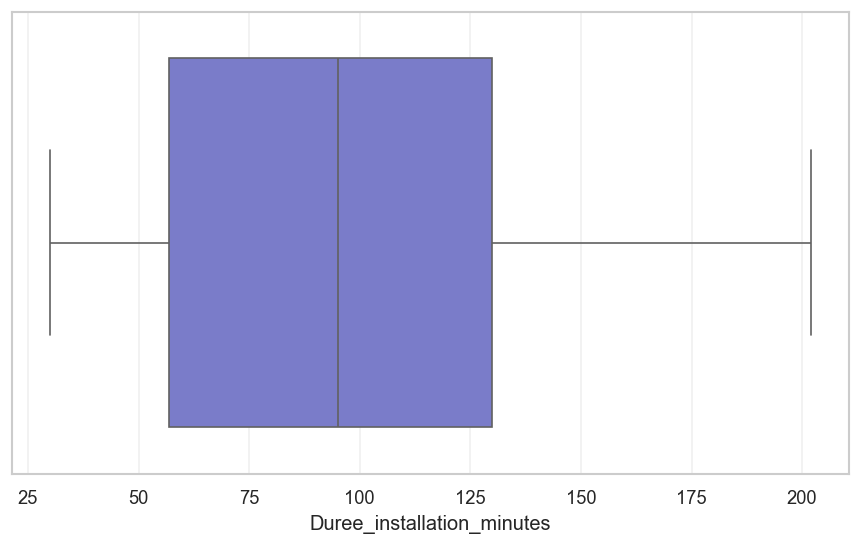

In [176]:
sns.boxplot(x=df['Duree_installation_minutes']) 

Il n y a pas de valeurs aberrantes dans les colonnes `Debit_reseau_Mbps` et `Duree_installation_minutes`

<Axes: xlabel='date_installation'>

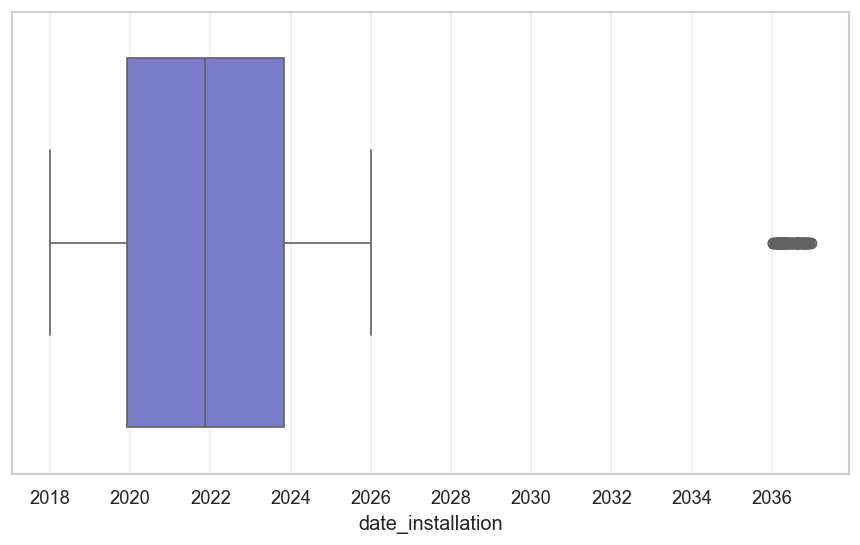

In [177]:
sns.boxplot(x=df['date_installation']) 

In [178]:
Q1 = df['date_installation'].quantile(0.25)
Q3 = df['date_installation'].quantile(0.75)
IQR = Q3 - Q1
df = df[(df['date_installation'] > Q1 - 1.5 * IQR) & (df['date_installation'] < Q3 + 1.5 * IQR)]
print(df["date_installation"].value_counts())
print(Q1, Q3, IQR)

date_installation
2020-11-09    14
2022-07-16    14
2024-06-06    14
2019-12-26    13
2019-06-12    13
              ..
2024-12-19     1
2018-04-27     1
2024-12-05     1
2018-04-06     1
2018-09-28     1
Name: count, Length: 2893, dtype: int64
2019-12-04 00:00:00 2023-10-29 00:00:00 1425 days 00:00:00


la méthode IQR à détecter une valeur aberrente la data 2032 qu'il faut la supprimer 

> *Méthode 3* : Z-score

* distribution normale ou non :

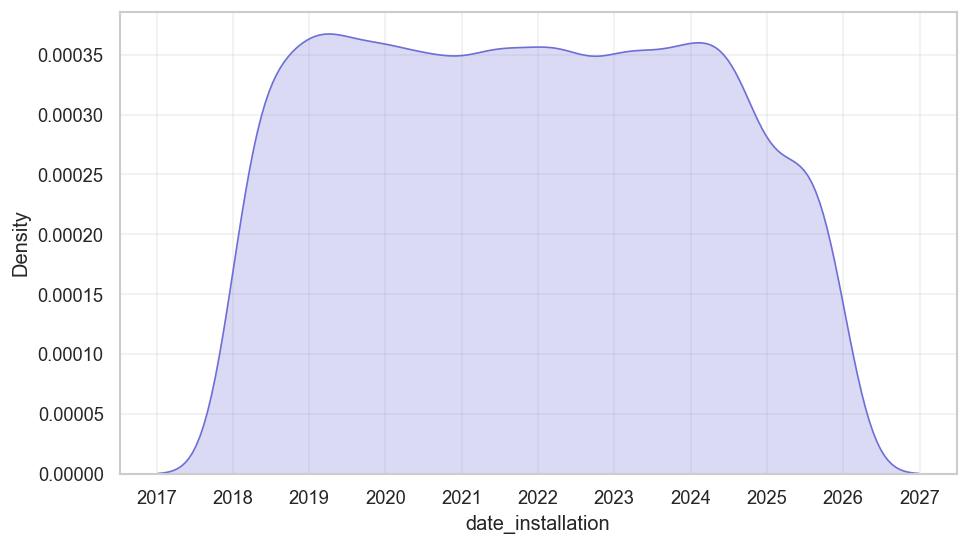

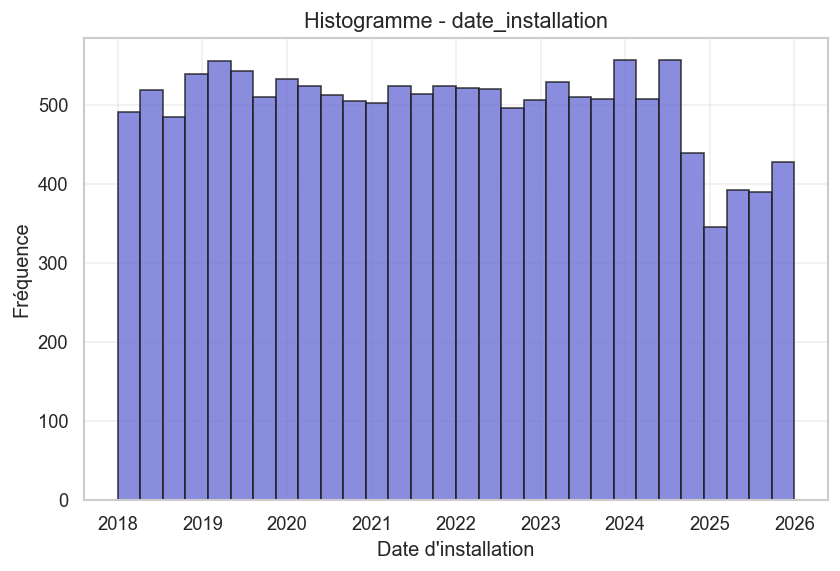

In [179]:
import scipy.stats as stats
from scipy.stats import kstest
import matplotlib.pyplot as plt

sns.kdeplot(df['date_installation'], fill=True)

plt.figure(figsize=(8,5))
plt.hist(df["date_installation"], bins=30, edgecolor='k', alpha=0.8)
plt.title("Histogramme - date_installation")
plt.xlabel("Date d'installation")
plt.ylabel("Fréquence")
plt.show()

## 4. Préparation des données

### 4.1 Nettoyage des données

* Nettoyage des valeurs abérrantes :

In [180]:
df = df[df["nombre_reclamations_client"]!=-2]

* Correction de l'incohérence des données dans `Systeme_exploitation_poste` :

In [181]:
df['Systeme_exploitation_poste'] = df['Systeme_exploitation_poste'].replace(
    ['win10', 'Win 10', 'Win10'],'Win10')

* Nettoyage des valeurs nulles:

si le porcentage de valeur manquante est inferieur à 5% alors on supprime les lignes avec des valeurs manquantes sinon on impute

In [182]:
#df = df.dropna(subset=["Id_Client"])
threshold = len(df) * 0.05
cols_to_drop = df.columns[(df.isna().sum() <= threshold) & (df.isna().sum() > 0)]
print(cols_to_drop)
df.dropna(subset=cols_to_drop, inplace=True )

Index(['Id_Client', 'installation_reussie'], dtype='str')


In [183]:
df["Remarques"].isna().sum() / len(df) * 100

np.float64(46.350067842605156)

on a 12% > a 5% d'ou on peut pas supprimer il faut bien remplacer les valeurs manquantes

### 4.2 Imputation des valeurs manquantes basée sur l’analyse statistique

### 4.2.1 Analyse des relations entre variables

* Dependance entre la variable `Remarques` et les variables qualitatives :

In [184]:
cat_cols = [
    'Nom_produit', 'Gouvernorat', 'Type_client',
    'Systeme_exploitation_poste', 'client_a_reclame',
    'client_satisfait', 'Technicien_ID',
    'Mode_installation', 'Tentative_installation_weekend',
    'version_produit','Version_precedente', 'installation_reussie'
]

In [185]:
from scipy.stats import chi2_contingency

results_chi2 = []

for col in cat_cols:
    ct = pd.crosstab(df[col], df["Remarques"])
    
    chi2, p, dof, Et = chi2_contingency(ct)
    
    # condition
    valid = (Et >= 5).all()
    
    results_chi2.append({
        "variable": col,
        "p_value": p,
        "dependence": p < 0.05,
        "condition_ok": valid
    })

pd.DataFrame(results_chi2).sort_values("p_value")

,variable,p_value,dependence,condition_ok
9,version_produit,0.000000e+00,True,True
2,Type_client,5.924725e-44,True,True
3,Systeme_exploitation_poste,1.621869e-35,True,False
1,Gouvernorat,1.388453e-14,True,True
7,Mode_installation,1.226001e-11,True,True
0,Nom_produit,6.158839e-10,True,True
11,installation_reussie,1.630051e-01,False,True
6,Technicien_ID,3.158242e-01,False,True
4,client_a_reclame,3.586680e-01,False,False
8,Tentative_installation_weekend,3.848480e-01,False,True


- dependance avec `version_produit`, `Type_client`, `Gouvernorat`, `Mode_installation` et `Nom_produit` 
- test khi deux ne marche pas sur Systeme_exploitation_poste il faut faire un autre test
- explication mathématiques du khi deux 

cas de `Nom_produit`:

In [186]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Nom_produit'], df['Remarques'])
chi2, p, _, _ = chi2_contingency(table)
print(p)

6.158839388360471e-10


- 0.02 < 0.05 donc il y a dependence entre les deux variables 
- on constate qu'il ya une dependence siginificative entre les deux variables `Nom_produit` et `Remarques` d'ou l'idee dimputer selon le nom de porduit est possible

    Cas 1 : manque espace disque

In [187]:
pd.crosstab(df['Nom_produit'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Nom_produit,,,,,,,
GRB,0.136620,0.106831,0.099127,0.089882,0.095532,0.097586,0.374422
INSAF,0.131231,0.111902,0.110376,0.108342,0.098169,0.085961,0.354018
MADANIA,0.149096,0.103414,0.109438,0.095884,0.106928,0.097390,0.337851
MAKATIB,0.124314,0.089366,0.097354,0.163255,0.097354,0.083375,0.344983


- Pour la remarque manque espace disque est particulièrement élevé pour MAKATIB (0.149)
- Pour les autres remarques ils ont des valeurs proches entre produits donc on ne peut rien dire

In [188]:
pd.crosstab(df['Taille_site_postes'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Taille_site_postes,,,,,,,
1,0.114286,0.131429,0.102857,0.097143,0.085714,0.131429,0.337143
2,0.121053,0.084211,0.084211,0.100000,0.110526,0.100000,0.400000
3,0.136612,0.120219,0.125683,0.092896,0.076503,0.114754,0.333333
4,0.153226,0.090323,0.103226,0.090323,0.093548,0.091935,0.377419
5,0.159204,0.092869,0.111111,0.086235,0.101161,0.086235,0.363184
6,0.124797,0.102107,0.121556,0.090762,0.108590,0.105348,0.346840
7,0.165094,0.100629,0.108491,0.094340,0.095912,0.084906,0.350629
8,0.178571,0.115646,0.091837,0.079932,0.102041,0.091837,0.340136
9,0.122241,0.120543,0.098472,0.098472,0.089983,0.083192,0.387097


- Quand `Taille_site_postes` supérieur ou égal à 26 le taux de `Remarques` manque espace disque augmente

> Regle 1 : imputer `Remarque` par manque espace disque quand le `Nom_produit` est MAKATIB et `Taille_site_postes` supérieur ou égal à 26 

    Cas 2 : version incompatible

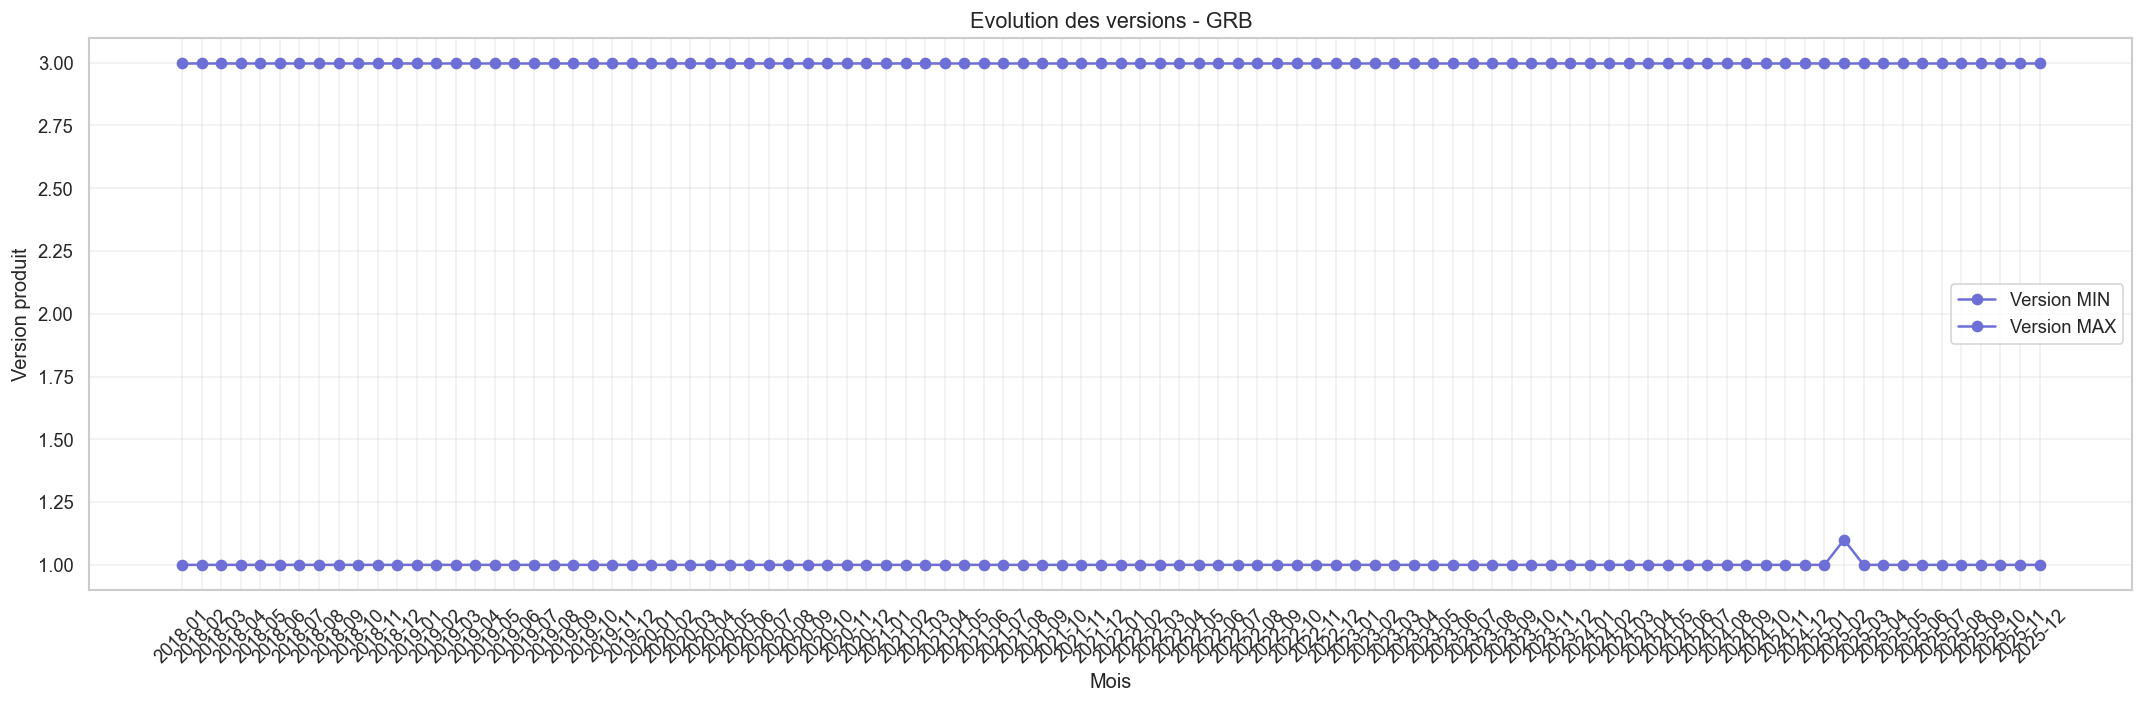

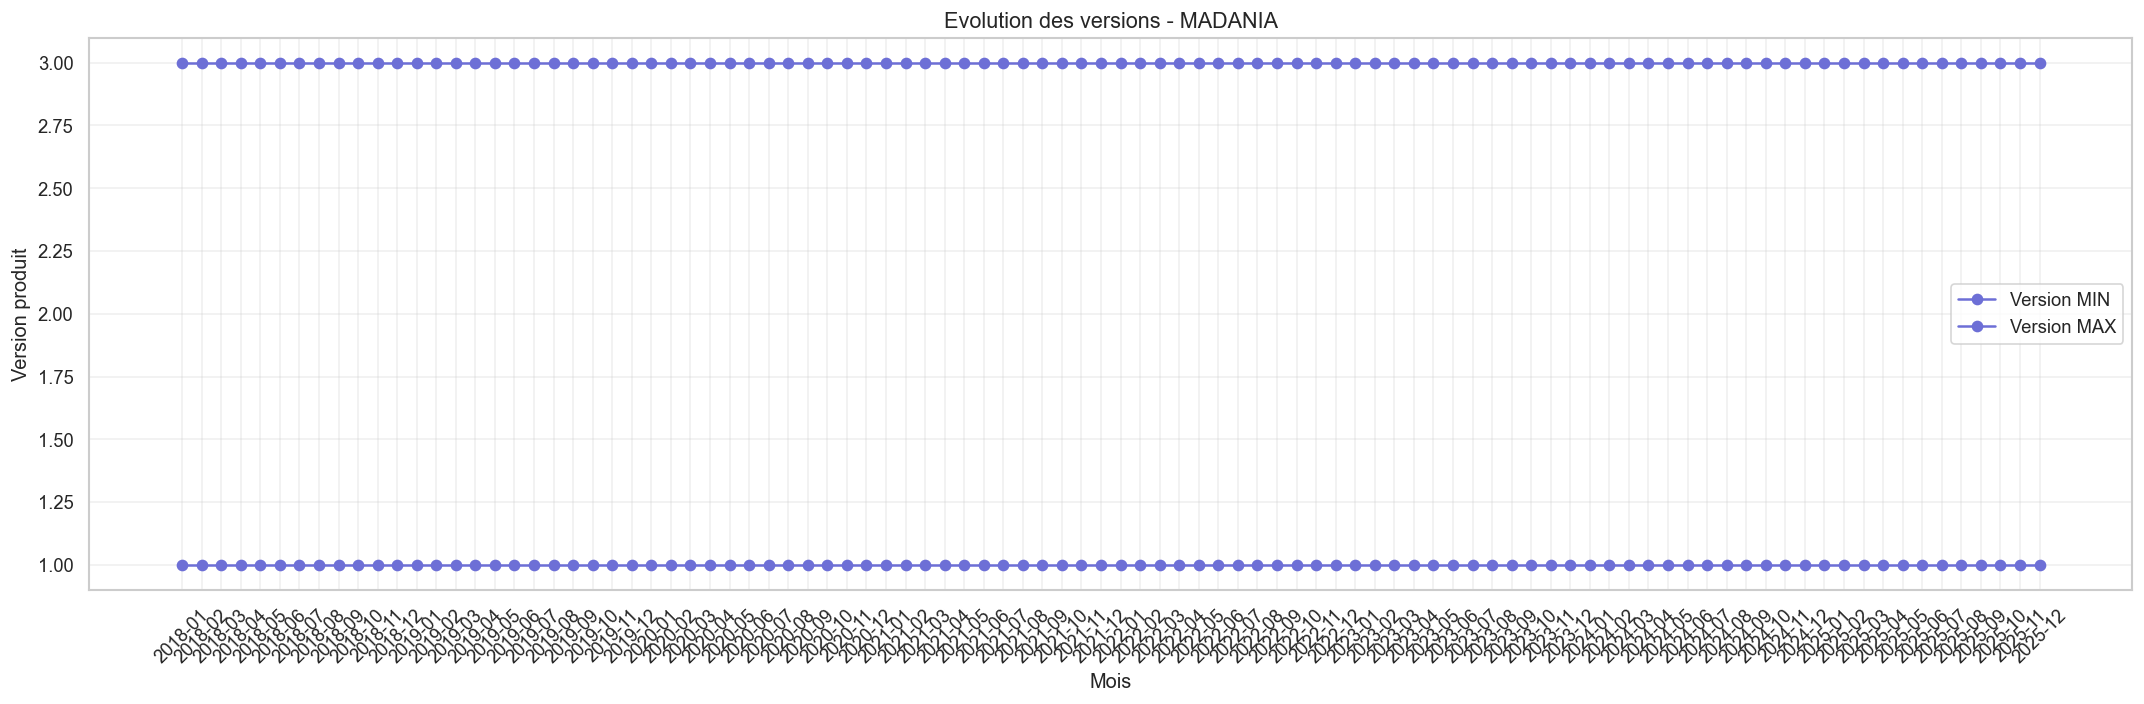

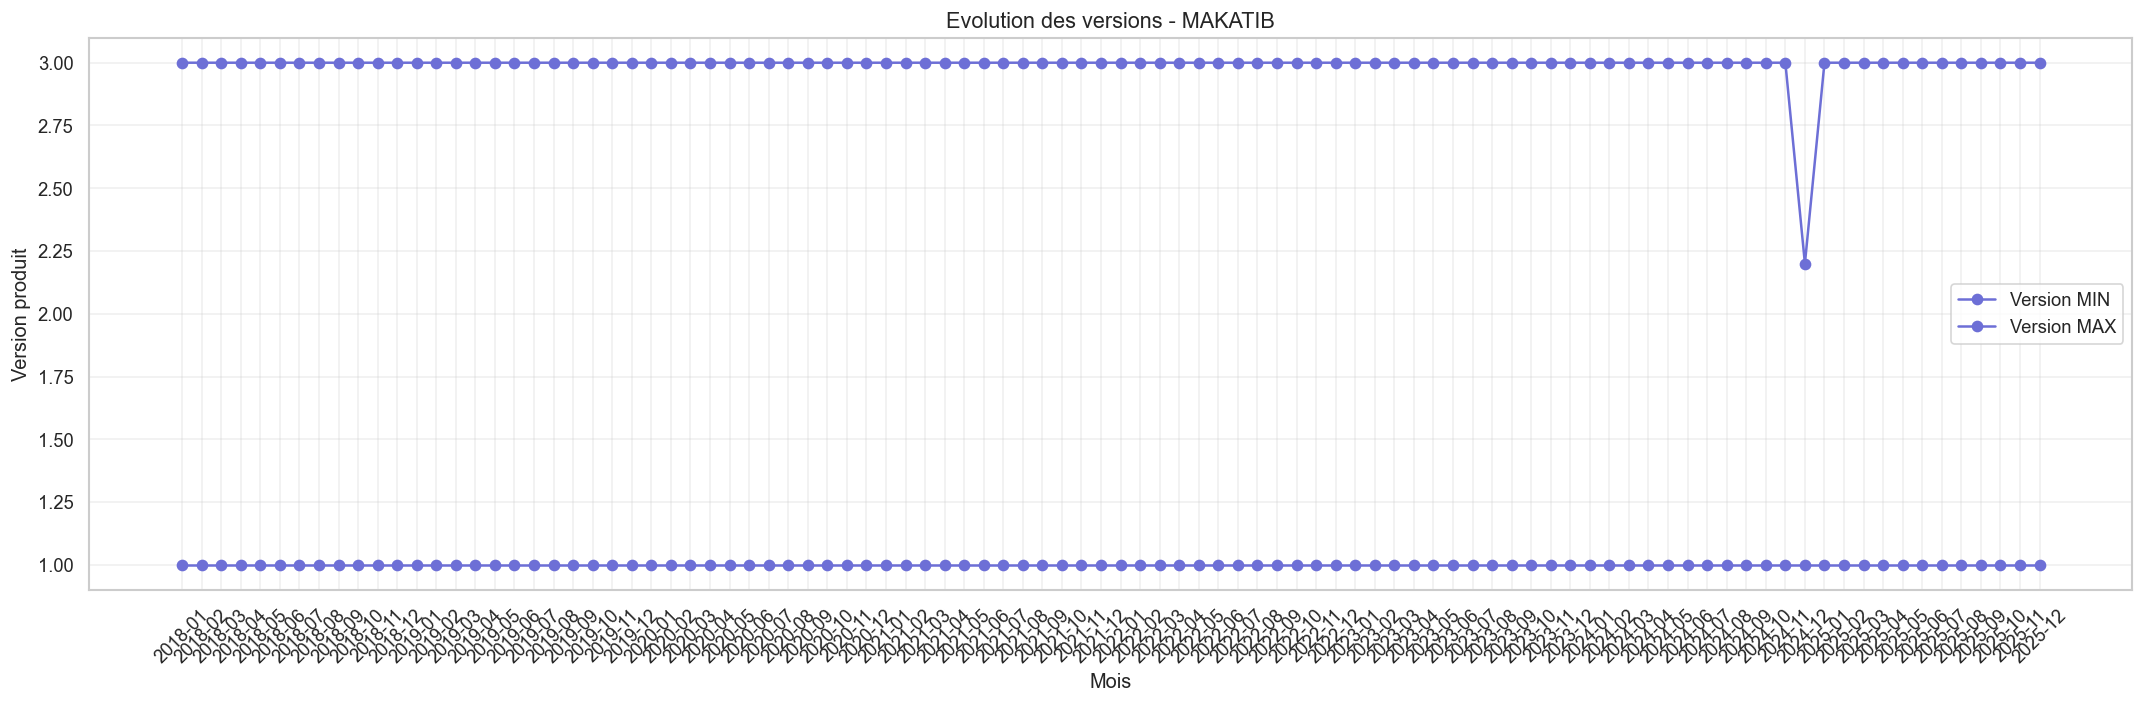

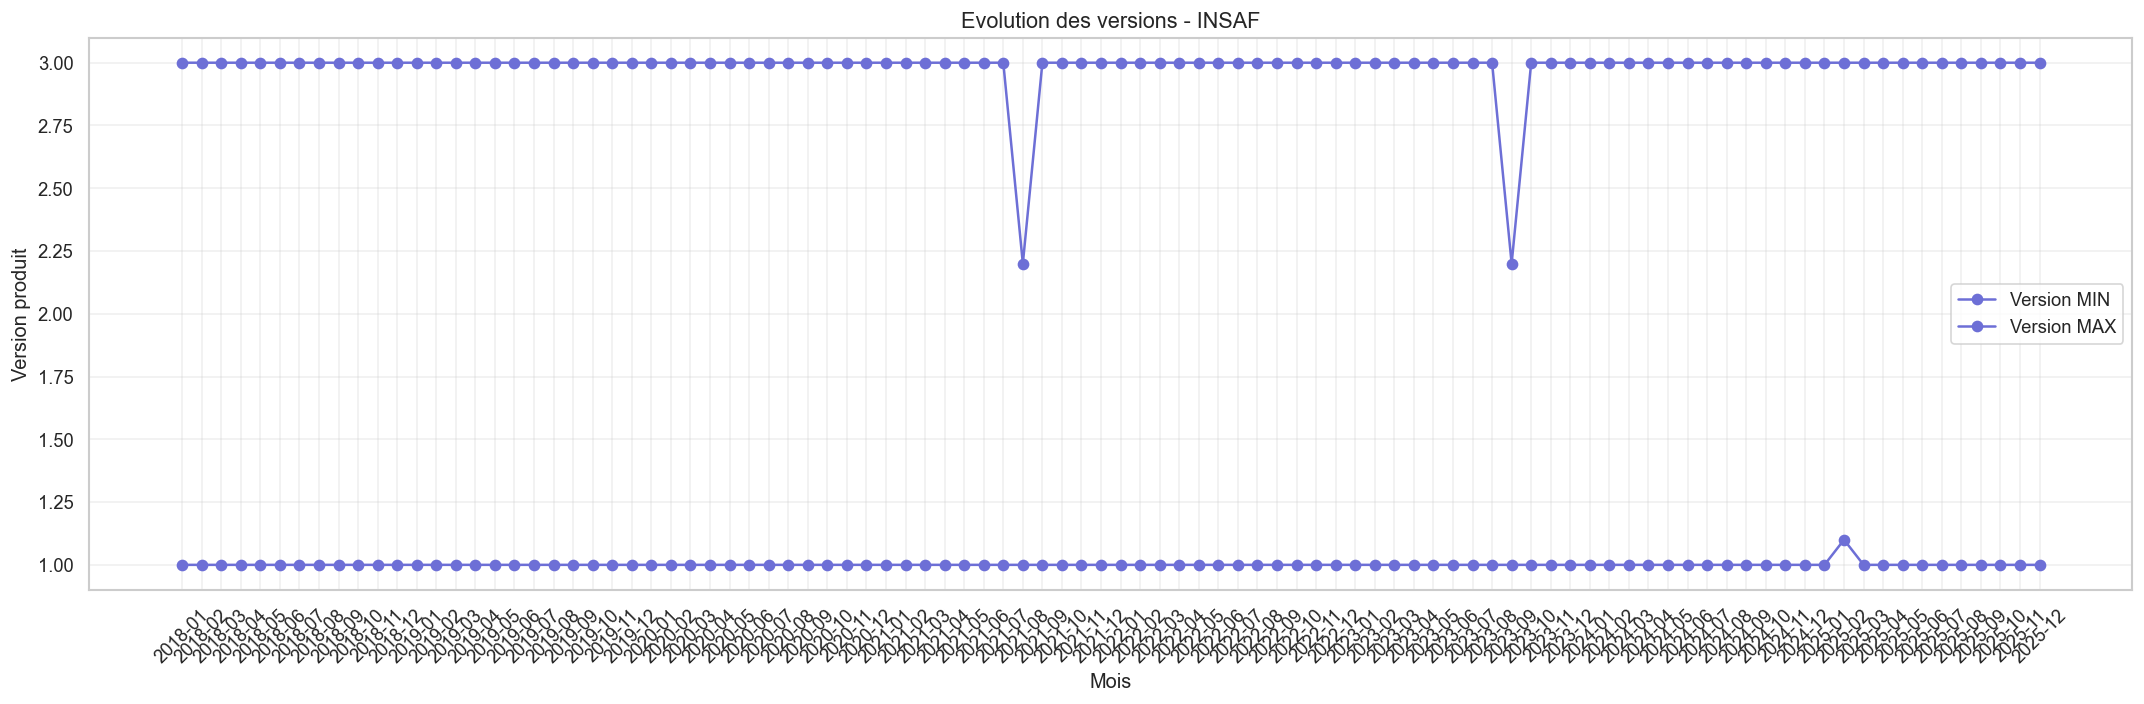

In [189]:
df = df.copy()

df['version_produit'] = pd.to_numeric(df['version_produit'], errors='coerce')
df['date_installation'] = pd.to_datetime(df['date_installation'])

df['mois'] = df['date_installation'].dt.to_period('M')

produits = ['GRB', 'MADANIA', 'MAKATIB', 'INSAF']

for produit in produits:
    
    subset = df[df['Nom_produit'] == produit]
    
    agg = subset.groupby('mois')['version_produit'].agg(['min', 'max']).reset_index()
    plt.figure(figsize=(18, 6))
    
    plt.plot(agg['mois'].astype(str), agg['min'], marker='o', label='Version MIN')
    plt.plot(agg['mois'].astype(str), agg['max'], marker='o', label='Version MAX')
    
    plt.title(f"Evolution des versions - {produit}")
    plt.xlabel("Mois")
    plt.ylabel("Version produit")
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    
df = df.drop(columns="mois")
df['version_produit'] = df['version_produit'].astype(object)

- L'écart élevé entre les versions installées reflète une mauvaise synchronisation des mises à jour, ce qui peut engendrer des anomalies fonctionnelles, notamment des problèmes de compatibilité entre versions.

> Regle 2 : imputer `Remarque` par version incompatible quand il y a l'écart entre le min et le max des `version_produit` installer durant ce mois est superieur à 1

    Cas 3 : Problème adressage ip

In [190]:
pd.crosstab(df['Type_client'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Type_client,,,,,,,
Collectivité locale,0.112208,0.122597,0.101818,0.092468,0.100779,0.102338,0.367792
EPA,0.108869,0.100903,0.107807,0.108869,0.100903,0.086564,0.386086
EPNA,0.218182,0.089952,0.103349,0.086124,0.099043,0.087081,0.316268
Ministère,0.096020,0.099005,0.103483,0.170647,0.097512,0.088557,0.344776


- La `Remarques` Problème adressage ip est particulièrement élevé pour EPNA (0.169)
- Pour les autres remarques ils ont des valeurs proches entre `Type_client` donc on ne peut rien dire

In [191]:
pd.crosstab(df['Mode_installation'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Mode_installation,,,,,,,
Technicien_sur_site,0.106383,0.107152,0.113561,0.114073,0.103563,0.087670,0.367598
Télémaintenance,0.163464,0.098577,0.094834,0.115049,0.095583,0.094335,0.338158


- La `Remarques` Problème adressage ip est particulièrement élevé pour Télémaintenance (0.166898)
- Pour les autres remarques ils ont des valeurs proches entre `Mode_installation` donc on ne peut rien dire

In [192]:
pd.crosstab(df['Gouvernorat'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Gouvernorat,,,,,,,
Ariana,0.107649,0.087819,0.101983,0.096317,0.093484,0.099150,0.413598
Ben Arous,0.140056,0.112045,0.120448,0.112045,0.109244,0.114846,0.291317
Bizerte,0.111486,0.131757,0.125000,0.114865,0.094595,0.087838,0.334459
Béja,0.179710,0.069565,0.098551,0.150725,0.113043,0.066667,0.321739
Gabès,0.106195,0.120944,0.091445,0.109145,0.103245,0.079646,0.389381
Gafsa,0.224684,0.063291,0.075949,0.075949,0.098101,0.091772,0.370253
Jendouba,0.225610,0.079268,0.073171,0.088415,0.112805,0.091463,0.329268
Kairouan,0.135057,0.103448,0.129310,0.135057,0.074713,0.114943,0.307471
Kasserine,0.199367,0.104430,0.056962,0.101266,0.107595,0.066456,0.363924


- La `Remarques` Problème adressage ip est particulièrement élevé pour Gafsa, Jendouba, Kasserine, Médenine, Tataouine (entre 0.2 et 0.24)
- La `Remarques` poste obsolète est particulièrement élevé pour Gafsa, Jendouba, Kasserine, Médenine, Tataouine
- Pour les autres remarques ils ont des valeurs proches entre `Gouvernorat` donc on ne peut rien dire

> Regle 3 : imputer `Remarque` par Problème adressage ip quand `Type_client` EPNA, `Mode_installation` Télémaintenance et `Gouvernorat` appartient à {Gafsa, Jendouba, Kasserine, Médenine, Tataouine}

    Cas 4 : erreur configuration poste

In [193]:
pd.crosstab(df['Systeme_exploitation_poste'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Systeme_exploitation_poste,,,,,,,
Unknown,0.000000,0.000000,0.812500,0.000000,0.156250,0.000000,0.031250
Win10,0.128060,0.096045,0.102637,0.121469,0.091337,0.103578,0.356874
Win11,0.144385,0.112299,0.100535,0.103743,0.111230,0.091979,0.335829
Win7,0.116736,0.100207,0.111570,0.137397,0.120868,0.073347,0.339876
Win8,0.142127,0.089980,0.092025,0.114519,0.091002,0.099182,0.371166
Windows 2008 Server,0.141372,0.107069,0.088358,0.141372,0.092516,0.085239,0.344075
Windows 2012 Server,0.133333,0.105820,0.099471,0.113228,0.087831,0.091005,0.369312
Windows server 2016,0.137048,0.105422,0.075301,0.096386,0.099398,0.094880,0.391566
Windows server 2019,0.155629,0.104305,0.105960,0.094371,0.099338,0.084437,0.355960


- Les `Remarques` erreur configuration est particulièrement élevé pour Unknown et WindowsXP
- Pour les autres remarques ils ont des valeurs proches entre `Systeme_exploitation_poste` donc on ne peut rien dire

In [194]:
pd.crosstab(df['version_produit'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
version_produit,,,,,,,
1.0,0.097103,0.039154,0.057165,0.076742,0.047768,0.041504,0.640564
1.1,0.103110,0.067103,0.076105,0.075286,0.057283,0.052373,0.568740
1.2,0.090595,0.071613,0.065574,0.068162,0.067299,0.054357,0.582399
2.0,0.181066,0.161765,0.131434,0.132353,0.146140,0.113971,0.133272
2.1,0.165587,0.153562,0.140611,0.154487,0.120259,0.119334,0.146161
2.2,0.166350,0.127376,0.137833,0.161597,0.145437,0.124525,0.136882
3.0,0.159378,0.118562,0.137026,0.151603,0.132167,0.151603,0.149660


- Les `Remarques` erreur configuration et poste obsolète sont particulièrement élevé pour `version_produit`supérieur ou égal à 2.0
- Pour les autres remarques ils ont des valeurs proches entre `version_produit` donc on ne peut rien dire

> Regle 4 : imputer `Remarque` par erreur configuration poste quand `Systeme_exploitation_poste` est Unkown ou WindowsXP et `version_produit`supérieur ou égal à 2.0

    Cas 5 : poste obsolète

> Regle 5 : imputer `Remarque` par poste obsolète quand `version_produit`supérieur ou égal à 2.0 et `Gouvernorat` appartient à {Gafsa, Jendouba, Kasserine, Médenine, Tataouine}

* Dependanc entre la variable `Remarques` et les variables qualitatives :

In [195]:
num_cols = [
    'nombre_essais_installation',
    'nombre_reclamations_client', 'Duree_installation_minutes',
    'Debit_reseau_Mbps', 'Taille_site_postes'
]

In [196]:
X = df[num_cols].astype(float)
le = LabelEncoder()
y = le.fit_transform(df["Remarques"].astype(str))
mi = mutual_info_classif(X, y, random_state=0)
mi_results = pd.DataFrame({
    "Variable": num_cols,
    "Mutual Information": mi
}).sort_values(by="Mutual Information", ascending=False)

print(mi_results)

                     Variable  Mutual Information
0  nombre_essais_installation            0.414919
1  nombre_reclamations_client            0.392030
2  Duree_installation_minutes            0.336360
3           Debit_reseau_Mbps            0.283639
4          Taille_site_postes            0.056997


- L’information mutuelle obtenue (0.226) indique que le débit réseau contient une information statistiquement significative sur les remarques, mais cette dépendance est partielle et probablement concentrée sur certaines remarques car la répartiton est déséquilibrée
- Pour les autres variable l'information mutuelle obtenue est proche de 0 ce qui signifie qu'il n y a pas de dépendance avec `Remarques`

In [197]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

# X
X = df[["Debit_reseau_Mbps"]].astype(float)

# y
le = LabelEncoder()
y = le.fit_transform(df["Remarques"].astype(str))

# MI
mi = mutual_info_classif(X, y)

print(mi)

[0.28513749]


    Cas 6 : connexion serveur lente et problème réseau

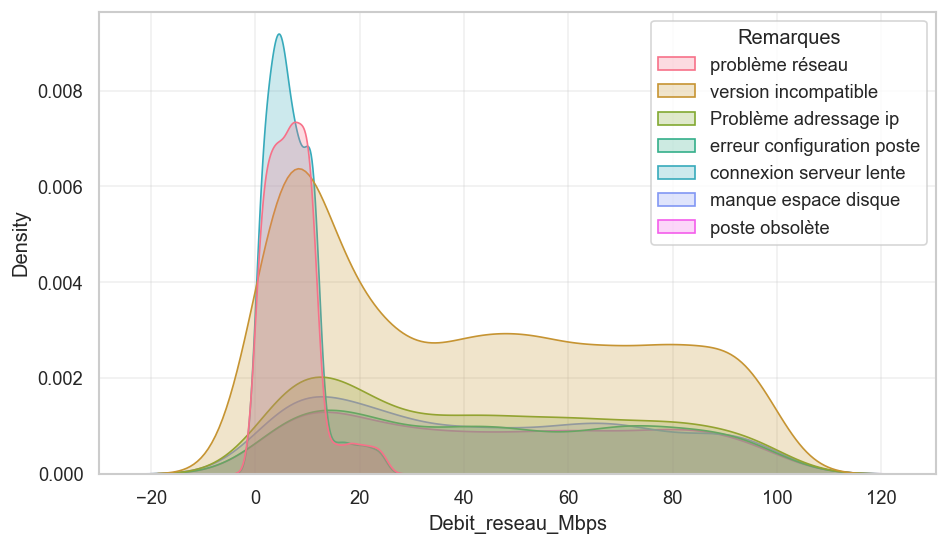

In [198]:
sns.kdeplot(data=df, x="Debit_reseau_Mbps", hue="Remarques", fill=True)
plt.show()

<Axes: xlabel='Remarques', ylabel='Debit_reseau_Mbps'>

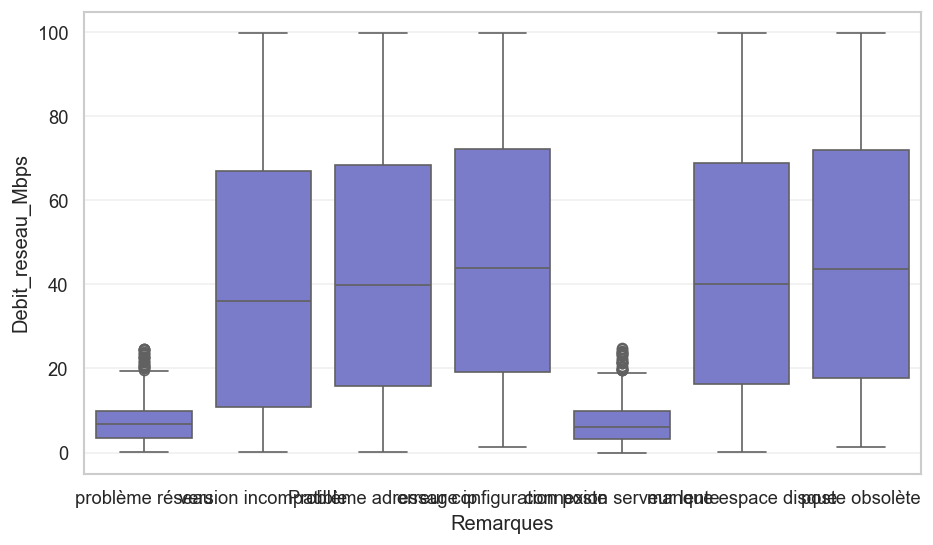

In [199]:
import seaborn as sns

sns.boxplot(x="Remarques", y="Debit_reseau_Mbps", data=df)

On remarque que le débit réseau influence surtout les problèmes liés directement à la connectivité comme `connexion serveur lente` et `problème réseau`. Les autres types de remarques ne semblent pas dépendre du débit.

on constate qu'il ya une dependence siginificative entre les deux variables `Debit_reseau_Mbps` et `Remarques` d'ou l'idee dimputer selon le `Debit_reseau_Mbps` est possible

In [200]:
df.groupby("Remarques")["Debit_reseau_Mbps"].mean()

Remarques
Problème adressage ip         42.889084
connexion serveur lente        6.854416
erreur configuration poste    46.170158
manque espace disque          43.545254
poste obsolète                45.938056
problème réseau                7.090806
version incompatible          40.441775
Name: Debit_reseau_Mbps, dtype: float64

> Regle 6 : imputer `Remarque` par connexion serveur lente ou problème réseau quand `Debit_reseau_Mbps` est inférieur ou égal à 6

### 4.2.2 Nettoyage des valeurs manquantes dans la colonne `Remarques`

In [201]:
import numpy as np

mask_missing = df["Remarques"].isna()

# -------------------------
# Règle 0 (TA CONDITION)
# -------------------------
mask_ok = (
    (df["installation_reussie"] == "oui") &
    (df["client_satisfait"] == "oui")
)

df.loc[mask_ok, "Remarques"] = "Aucune"

# -------------------------
# Règle 1
# -------------------------
df.loc[
    mask_missing &
    (df["Nom_produit"] == "MAKATIB") &
    (df["Taille_site_postes"] >= 26),
    "Remarques"
] = "manque espace disque"

# -------------------------
# Règle 2
# -------------------------
df.loc[
    mask_missing &
    (df.groupby(df["date_installation"].dt.to_period("M"))["version_produit"]
        .transform(lambda x: x.max() - x.min()) > 1),
    "Remarques"
] = "version incompatible"

# -------------------------
# Règle 3
# -------------------------
gouvernorats_risque = ["Gafsa", "Jendouba", "Kasserine", "Médenine", "Tataouine"]

df.loc[
    mask_missing &
    (df["Type_client"] == "EPNA") &
    (df["Mode_installation"] == "Télémaintenance") &
    (df["Gouvernorat"].isin(gouvernorats_risque)),
    "Remarques"
] = "Problème adressage ip"

# -------------------------
# Règle 4
# -------------------------
df.loc[
    mask_missing &
    (df["Systeme_exploitation_poste"].isin(["Unknown", "WindowsXP"])) &
    (df["version_produit"] >= 2.0),
    "Remarques"
] = "erreur configuration poste"

# -------------------------
# Règle 5
# -------------------------
df.loc[
    mask_missing &
    (df["version_produit"] >= 2.0) &
    (df["Gouvernorat"].isin(gouvernorats_risque)),
    "Remarques"
] = "poste obsolète"

# -------------------------
# Règle 6
# -------------------------
mask = mask_missing & (df["Debit_reseau_Mbps"] <= 8)

df.loc[mask, "Remarques"] = np.random.choice(
    ["connexion serveur lente", "problème réseau"],
    size=mask.sum()
)

In [202]:
df.isna().sum()

Nom_produit                       0
version_produit                   0
date_installation                 0
Gouvernorat                       0
Id_Client                         0
Type_client                       0
Systeme_exploitation_poste        0
installation_reussie              0
nombre_essais_installation        0
client_a_reclame                  0
nombre_reclamations_client        0
client_satisfait                  0
Remarques                         0
Technicien_ID                     0
Duree_installation_minutes        0
Debit_reseau_Mbps                 0
Taille_site_postes                0
Mode_installation                 0
Tentative_installation_weekend    0
Version_precedente                0
dtype: int64

* Remplacer Unknown par WindowsXP dans `Systeme_exploitation_poste` :

In [203]:
df["Systeme_exploitation_poste"] = df["Systeme_exploitation_poste"].replace("Unknown","WindowsXP")

In [204]:
df["Systeme_exploitation_poste"].value_counts()

Systeme_exploitation_poste
Win10                  2351
Win11                  2259
Windows server 2022    1927
Windows server 2019    1921
Windows server 2016    1886
Win8                   1079
Win7                   1069
Windows 2012 Server    1059
Windows 2008 Server    1059
WindowsXP               130
Name: count, dtype: int64

In [205]:
df["Mode_installation"].value_counts()

Mode_installation
Technicien_sur_site    7377
Télémaintenance        7363
Name: count, dtype: int64

In [206]:
df["Remarques"].value_counts()

Remarques
version incompatible          8662
poste obsolète                1574
Problème adressage ip         1146
manque espace disque           899
connexion serveur lente        835
erreur configuration poste     819
problème réseau                742
Aucune                          63
Name: count, dtype: int64

In [207]:
df.to_csv("installations_produits_CNI_clean.csv", index=False, sep=";", encoding="cp1252")

## 5. Feature engineering

### 5.1 Regroupement de certaines modalités

In [208]:
# taille du site :

def cat_taille(x):
    if x <= 10:
        return "petit"
    elif x <= 20:
        return "moyen"
    else:
        return "grand"

df["cat_taille"] = df["Taille_site_postes"].apply(cat_taille)

In [209]:
# Debit reseau :

def cat_debit(x):
    if x < 5:
        return "faible"
    elif x < 20:
        return "moyen"
    else:
        return "bon"

df["cat_debit"] = df["Debit_reseau_Mbps"].apply(cat_debit)

In [210]:
# zone d'urbanisation :

metropolitaine = [
    "Tunis", "Ariana", "Ben Arous", "Manouba",
    "Sfax", "Sousse", "Monastir", "Nabeul", "Bizerte"
]

mixte = [
    "Mahdia", "Kairouan", "Gabès", "Zaghouan",
    "Béja", "Siliana", "Le Kef", "Tozeur", "Gafsa"
]

rurale = [
    "Jendouba", "Kasserine", "Sidi Bouzid",
    "Médenine", "Tataouine", "Kébili"
]
def classify_region(x):
    if x in metropolitaine:
        return "metropolitaine"
    elif x in mixte:
        return "mixte"
    elif x in rurale:
        return "rurale"
    else:
        return "inconnu"

df["zone_urbanisation"] = df["Gouvernorat"].apply(classify_region)

### 5.2 Extraction de colonne

In [211]:
# Remarques :
df["pb_reseau"] = df["Remarques"].str.contains("réseau|connexion|serveur", case=False, na=False).astype(int)
df["pb_configuration"] = df["Remarques"].str.contains("configuration|adresse|ip", case=False, na=False).astype(int)
df["pb_materiel"] = df["Remarques"].str.contains("disque|poste|obsolète", case=False, na=False).astype(int)
df["pb_version"] = df["Remarques"].str.contains("version|incompatible", case=False, na=False).astype(int)
df["pb_aucun"] = df["Remarques"].str.contains("Aucun|Aucune", case=False, na=False).astype(int)

In [212]:
# variable temporelle :

df["annee"] = df["date_installation"].dt.year
df["jour_semaine"] = df["date_installation"].dt.dayofweek
df["mois"] = df["date_installation"].dt.to_period("M").astype(str)

In [213]:
# variable version :

df["upgrade"] = (df["version_produit"] == df["version_produit"].max()).astype("int")

In [214]:
# variable de satisfaction :

df["score_risque"] = (
    # réseau faible
    (df["Debit_reseau_Mbps"] < 5).astype(int) +

    # installation difficile
    (df["nombre_essais_installation"] > 2).astype(int) +

    # durée trop longue
    (df["Duree_installation_minutes"] > 120).astype(int) +

    # OS instable / ancien
    (df["Systeme_exploitation_poste"].str.contains("WindowsXP", case=False, na=False)).astype(int) +

    # produits historiquement problématiques (selon ton domaine)
    (df["Nom_produit"].isin(["GRB"])).astype(int) +

    # anciennes versions = plus de bugs
    (df["version_produit"].astype(str).str.contains("1\\.|2\\.|3\\.", na=False)).astype(int) +

    # taille site complexe
    (df["Taille_site_postes"] > 15).astype(int) +
    
    # gouvernorat
    (df["Gouvernorat"].isin(["Gafsa", "Jendouba", "Kasserine", "Médenine", "Tataouine"])).astype(int)
)

df["client_risque"] = (df["score_risque"] >= 3).astype(int)

### 5.3 Encodage des variables

In [215]:
# Encodage sur la dataframe qu'on va utiliser pour poduire des modeles fiables 

# Variables catégorielles binaires:
binary_cols = [
    "installation_reussie",
    "client_satisfait",
    "client_a_reclame",
    "Tentative_installation_weekend"
]

for col in binary_cols:
    df[col+'_encoded'] = df[col].map({"oui":1, "non":0})

In [216]:
# Version produit

df["version_produit_o"] = df["version_produit"]
df["version_produit_encoded"] = df.groupby("version_produit")["installation_reussie_encoded"].transform("mean")


In [217]:
# OS 

df["os_enc"] = df.groupby("Systeme_exploitation_poste")["installation_reussie_encoded"].transform("mean")

In [218]:
for col in ["Nom_produit", "Type_client", "Mode_installation","cat_taille", "cat_debit","zone_urbanisation"] : 
    df[col+"_o"] = df[col]

In [219]:
var_a_encoder = ["Nom_produit", "Type_client", "Mode_installation","cat_taille", "cat_debit","zone_urbanisation"]
df = pd.get_dummies(df, columns=var_a_encoder, drop_first=True)

 ## 6.Construction des KPI

In [220]:
df_kpi = df.copy()
var_a_effacer =["Nom_produit", 'date_installation', 'Gouvernorat',
       'Id_Client', 'Type_client', 'Systeme_exploitation_poste',
       'client_a_reclame',
       'Remarques', 'Technicien_ID',"version_produit",
       'Debit_reseau_Mbps', 'Taille_site_postes', 'Mode_installation',
       'Version_precedente',"cat_version", "cat_taille", "cat_debit", "zone_urbanisation",
       'score_risque', 'year',"installation_reussie","client_satisfait",
    "client_a_reclame","mois","Tentative_installation_weekend",
    "Nom_produit_o", "Type_client_o", "Mode_installation_o","cat_taille_o", "cat_debit_o","zone_urbanisation_o"]

df_kpi = df_kpi.drop(columns=var_a_effacer, errors='ignore')

### 6.1 Matrice de corrélation : Relation entre les variables

In [221]:
import plotly.express as px

coeff_corr = df_kpi.corr(method='pearson')

fig = px.imshow(
    coeff_corr,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1, zmax=1,
    aspect="auto"
)

fig.update_layout(
    title="Matrice de corrélation interactive",
    width=1400,   
    height=1200   
)

fig.update_traces(
    hovertemplate="X: %{x}<br>Y: %{y}<br>Corr: %{z:.2f}<extra></extra>"
)

fig.show()

### 6.2 KPI globaux

In [222]:
kpi_global = {
    "nb_installations": len(df), 
    "taux_reussite": df["installation_reussie_encoded"].mean(),
    "taux_satisfaction": df["client_satisfait_encoded"].mean(),
    "taux_reclamation": df["nombre_reclamations_client"].mean(),
    "duree_moyenne": df["Duree_installation_minutes"].mean(),
    "nb_moyen_essais": df["nombre_essais_installation"].mean()
}
kpi_global

{'nb_installations': 14740,
 'taux_reussite': np.float64(0.48656716417910445),
 'taux_satisfaction': np.float64(0.4386024423337856),
 'taux_reclamation': np.float64(1.653867028493894),
 'duree_moyenne': np.float64(94.5280868385346),
 'nb_moyen_essais': np.float64(3.5220488466757125)}

### 5.1 PRODUIT vs OS & DURÉE

In [223]:
kpi_produit = df.groupby("Nom_produit_o").agg({
    "Duree_installation_minutes": "mean",
    "installation_reussie_encoded": "mean"
}).rename(columns={
    "Duree_installation_minutes": "temps_moyen",
    "installation_reussie_encoded": "taux_reussite"
})

print(kpi_produit.head())

               temps_moyen  taux_reussite
Nom_produit_o                            
GRB              89.231763       0.511709
INSAF            95.558452       0.482711
MADANIA          96.949713       0.474993
MAKATIB          96.425040       0.476625


In [224]:
import plotly.express as px
pivot_os = pd.crosstab(df["Nom_produit_o"], df["Systeme_exploitation_poste"])

fig = px.imshow(
    pivot_os,
    text_auto=True,
    color_continuous_scale="RdBu",
    title="Produit vs Système d'exploitation"
)

fig.update_layout(height=500)
fig.show()

In [225]:
fig = px.box(
    df,
    x="Nom_produit_o",
    y="Duree_installation_minutes",
    color="Nom_produit_o",
    title="Durée d'installation par produit"
)

fig.update_layout(xaxis_tickangle=-45)
fig.show()

### 5.2 VERSION vs REMARQUES

In [226]:
kpi_version = df.groupby("version_produit")["Remarques"].count().sort_values(ascending=False)
print(kpi_version)

version_produit
1.0    2233
1.1    2192
2.0    2110
1.2    2103
2.1    2063
2.2    2021
3.0    2018
Name: Remarques, dtype: int64


In [227]:
kpi_version = df.groupby("version_produit")["Remarques"].count().reset_index()

fig = px.bar(
    kpi_version,
    x="version_produit",
    y="Remarques",
    color="Remarques",
    title="Remarques par version produit"
)

fig.show()

### 5.3 TYPE CLIENT vs TAILLE SITE

In [228]:
kpi_client = df.groupby("Type_client_o")["Taille_site_postes"].mean()
print(kpi_client)

Type_client_o
Collectivité locale    10.367397
EPA                    11.580477
EPNA                   11.405658
Ministère              19.288456
Name: Taille_site_postes, dtype: float64


In [229]:
fig = px.box(
    df,
    x="Type_client_o",
    y="Taille_site_postes",
    color="Type_client_o",
    title="Taille des sites par type client"
)

fig.show()

### 5.4 SUCCÈS INSTALLATION

In [230]:
kpi_success = {
    "taux_reussite": df["installation_reussie_encoded"].mean(),
    "moyenne_essais": df["nombre_essais_installation"].mean(),
    "temps_moyen": df["Duree_installation_minutes"].mean(),
    "taux_satisfaction": df["client_satisfait_encoded"].mean()
}
kpi_success

{'taux_reussite': np.float64(0.48656716417910445),
 'moyenne_essais': np.float64(3.5220488466757125),
 'temps_moyen': np.float64(94.5280868385346),
 'taux_satisfaction': np.float64(0.4386024423337856)}

In [231]:
import plotly.io as pio

df_grouped = df.groupby("installation_reussie")["nombre_essais_installation"].mean().reset_index()

fig = px.bar(
    df_grouped,
    x="installation_reussie",
    y="nombre_essais_installation",
    color="installation_reussie",
    color_discrete_map={0: "#e74c3c", 1: "#2ecc71"}
)

fig.show()

In [232]:
df_grouped2 = df.groupby("installation_reussie")["Duree_installation_minutes"].mean().reset_index()

fig = px.bar(
    df_grouped2,
    x="installation_reussie",
    y="Duree_installation_minutes",
    color="installation_reussie",
    title="Durée vs Réussite"
)
fig.show()

In [233]:
df_grouped3 = df.groupby("installation_reussie")["client_satisfait_encoded"].mean().reset_index()

fig = px.bar(
    df_grouped3,
    x="installation_reussie",
    y="client_satisfait_encoded",
    color="installation_reussie",
    title="Réussite vs Satisfaction",
    barmode="group"
)
fig.show()

### 5.5 NOMBRE ESSAIS (EFFORT TECHNIQUE)

In [234]:
kpi_essais = df["nombre_essais_installation"].describe()
kpi_essais

count    14740.000000
mean         3.522049
std          1.657813
min          1.000000
25%          2.000000
50%          4.000000
75%          5.000000
max          5.000000
Name: nombre_essais_installation, dtype: float64

In [235]:
df_grouped4 = df.groupby("nombre_essais_installation")["Duree_installation_minutes"].mean().reset_index()
fig = px.bar(
    df_grouped4,
    x="nombre_essais_installation",
    y="Duree_installation_minutes",
    title="Essais vs Durée (avec satisfaction)"
)

fig.show()

In [236]:
df_grouped5 = df.groupby("client_satisfait")["nombre_essais_installation"].mean().reset_index()
fig = px.bar(
    df_grouped5,
    y="client_satisfait",
    x="nombre_essais_installation",
    title="Essais vs Satisfaction"
)
fig.show()

### 5.6 RÉCLAMATIONS CLIENT

In [237]:
kpi_reclamation = {
    "taux_reclamation": df["client_a_reclame_encoded"].mean(),
    "moyenne_reclamations": df["nombre_reclamations_client"].mean()
}

kpi_reclamation

{'taux_reclamation': np.float64(0.5831071913161465),
 'moyenne_reclamations': np.float64(1.653867028493894)}

In [238]:
# Réclamation vs satisfaction
df_grouped6 = df.groupby("client_a_reclame")["client_satisfait_encoded"].mean().reset_index()
fig = px.bar(
    df_grouped6,
    x="client_a_reclame",
    y="client_satisfait_encoded",
    color="client_a_reclame",
    title="Impact des réclamations sur la satisfaction"
)

fig.show()

### 5.7 NOMBRE RÉCLAMATIONS

In [239]:
kpi_nb_reclam = df["nombre_reclamations_client"].describe()
print(kpi_nb_reclam)

count    14740.000000
mean         1.653867
std          1.898289
min          0.000000
25%          0.000000
50%          1.000000
75%          3.000000
max          6.000000
Name: nombre_reclamations_client, dtype: float64


In [240]:
fig = px.box(
    df,
    x="client_a_reclame",
    y="Duree_installation_minutes",
    color="client_a_reclame",
    title="Réclamation vs Durée"
)

fig.show()

### 5.8 SATISFACTION CLIENT

In [241]:
taux_satisfaction = df["client_satisfait_encoded"].mean()
print("Taux satisfaction:", taux_satisfaction)

Taux satisfaction: 0.4386024423337856


In [242]:
fig = px.box(
    df,
    x="client_satisfait",
    y="Duree_installation_minutes",
    color="client_satisfait",
    title="Satisfaction vs Durée"
)

fig.show()

### 5.81 KPI temporels

In [243]:
kpi_temporel = df.groupby('mois').agg({
    "installation_reussie_encoded": "mean",
    "client_satisfait_encoded": "mean",
    "nombre_reclamations_client": "mean",
    "nombre_essais_installation": "mean",
    "Duree_installation_minutes": "mean",
    "client_a_reclame_encoded": "mean"
}).reset_index()

kpi_temporel.head()

,mois,installation_reussie_encoded,client_satisfait_encoded,nombre_reclamations_client,nombre_essais_installation,Duree_installation_minutes,client_a_reclame_encoded
0,2018-01,0.516779,0.436242,1.664430,3.442953,95.671141,0.577181
1,2018-02,0.503311,0.483444,1.324503,3.364238,91.675497,0.549669
2,2018-03,0.516556,0.456954,1.668874,3.503311,92.476821,0.562914
3,2018-04,0.565517,0.482759,1.317241,3.365517,89.034483,0.544828
4,2018-05,0.503067,0.423313,1.785276,3.546012,97.092025,0.601227


In [244]:
import plotly.express as px

fig = px.line(
    kpi_temporel,
    x="mois",
    y="installation_reussie_encoded",
    markers=True,
    title="Évolution du taux de réussite"
)

fig.show()

In [245]:
fig = px.line(
    kpi_temporel,
    x="mois",
    y=["client_satisfait_encoded", "client_a_reclame_encoded"],
    markers=True,
    title="Satisfaction vs Réclamations dans le temps"
)

fig.show()

In [246]:
fig = px.line(
    kpi_temporel,
    x="mois",
    y="Duree_installation_minutes",
    markers=True,
    title="Évolution du temps d'installation"
)

fig.show()

In [247]:
fig = px.line(
    kpi_temporel,
    x="mois",
    y="nombre_essais_installation",
    markers=True,
    title="Évolution du nombre d'essais"
)

fig.show()

In [248]:
fig = px.line(
    kpi_temporel,
    x="mois",
    y="nombre_reclamations_client",
    markers=True,
    title="Évolution des réclamations"
)
fig.show()

In [249]:
fig = px.line(
    kpi_temporel,
    x="mois",
    y=["installation_reussie_encoded", "client_satisfait_encoded"],
    title="Drift qualité (réussite vs satisfaction)"
)

fig.show()

In [250]:
installations_temps = df.groupby("mois").size().reset_index(name="nombre_installations")
fig = px.line(
    installations_temps,
    x="mois",
    y="nombre_installations",
    markers=True,
    title="Nombre d'installations dans le temps"
)

fig.show()

- installation_reussie : Nom_produit(relation faible),version_produit(relation moyenne), Gouvernorat(relation tres faible) en relation avec Debit_reseau_Mbps(relation forte) et Remarques(relation forte) et Taille_site_postes(relation negative moyenne), Systeme_exploitation_poste(relation tres forte),Technicien_ID(relation positive moyenne), nombre_essais_installatio(relation négative tres forte), client_a_reclame(relation negative forte), nombre_reclamations_client(relation negative forte), client_satisfait(relation positive tres forte), Mode_installation(relation positive moyenne), Duree_installation_minutes(relation negative forte)

- client_satisfait : Nom_produit(relation faible), version_produit(relation faible),Remarques(relation negative forte), Debit_reseau_Mbps(relation positive moyenne), Mode_installation(relation faible), nombre_essais_installation(relation negative forte), Duree_installation_minutes(relation negative forte), installation_reussie(relation positive tres forte), client_a_reclame(relation negative tres forte), nombre_reclamations_client(relation negative tres forte)

- client_a_reclame : Nom_produit(relation faible), version_produit(relation moyenne), Systeme_exploitation_poste(relation positive moyenne/forte), Remarques(relation positive tres forte), Debit_reseau_Mbps(relation positive moyenne), nombre_essais_installation(relation positive tres forte), Duree_installation_minutes(relation positive forte), installation_reussie(relation negative tres forte),  nombre_reclamations_client(relation positive tres forte), client_satisfait(relation negative tres forte)

- Duree_installation_minutes : Nom_produit(relation forte pour makatib app 20gb), version_produit(relation positive faible/moyenne), Gouvernorat(relaion forte), Systeme_exploitation_poste(relaion tres forte), Remarques(relation moyenne), Debit_reseau_Mbps(relation negative tres forte), Mode_installation(relation moyenne), nombre_essais_installation(relation positive forte),Tentative_installation_weekend(relation moyenne), client_satisfait(relation négative moyenne), client_a_reclame(relation positive forte), nombre_reclamations_client(relation positive moyenne)

- nombre_essais_installation : Nom_produit(relation positive moyenne), version_produit(relation positive moyenne), Gouvernorat(relation forte), Systeme_exploitation_poste(relation positive forte), Remarques(relation positive tres forte), Debit_reseau_Mbps(relation negative forte), Mode_installation(relation positive faible), Duree_installation_minutes(relation positive tres forte), installation_reussie(relation negative tres forte), client_a_reclame(relation positive tres forte),nombre_reclamations_client(relation positive tres forte),client_satisfait(relation negative moyenne)

### 5.1 répartition des installations par gouvernorat :

In [251]:
sns.set_theme(style="whitegrid", palette="pastel")
plt.rcParams["figure.figsize"] = (10,6)

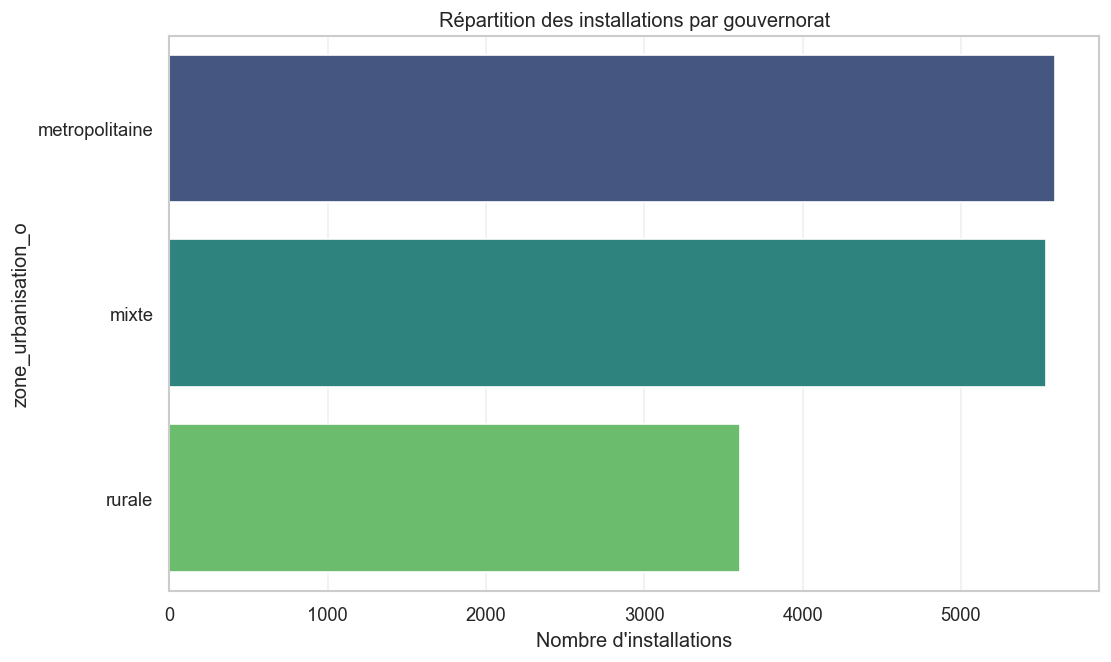

In [252]:
geo = df["zone_urbanisation_o"].value_counts().reset_index()
geo.columns = ["zone_urbanisation_o", "Installations"]

geo = geo.sort_values("Installations", ascending=False)

plt.figure()
sns.barplot(data=geo, x="Installations", y="zone_urbanisation_o", palette="viridis")

plt.title("Répartition des installations par gouvernorat")
plt.xlabel("Nombre d'installations")
plt.ylabel("zone_urbanisation_o")
plt.show()

- On constate que Mahdia à le plus d'installation

In [253]:
Nbre_installations_par_gouvernorat = df.groupby("zone_urbanisation_o")["zone_urbanisation_o"].count().sort_values(ascending=False)
Nbre_installations_par_gouvernorat

zone_urbanisation_o
metropolitaine    5594
mixte             5540
rurale            3606
Name: zone_urbanisation_o, dtype: int64

### 5.2 Distribution des installations selon le type de client :

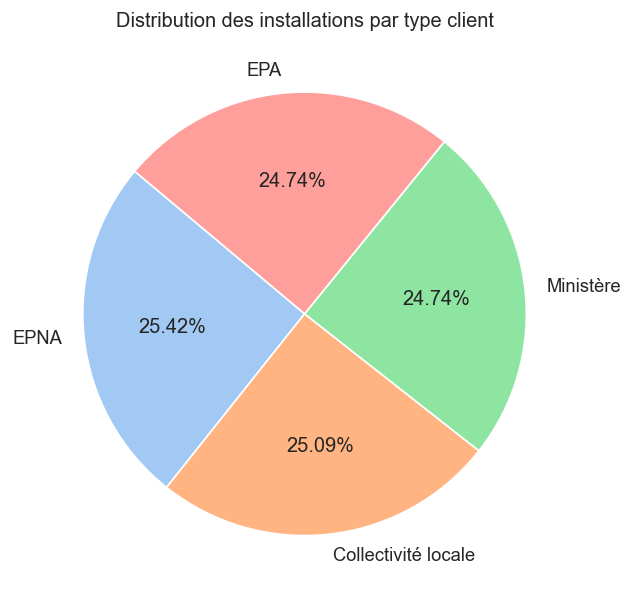

In [254]:
client = df["Type_client_o"].value_counts()

plt.figure()
plt.pie(client, labels=client.index, autopct='%1.2f%%',
        startangle=140, colors=sns.color_palette("pastel"))

plt.title("Distribution des installations par type client")
plt.show()

- L'écart entre la distribution des installations entre les differents type de client est présque identique

### 5.3 répartition des installations par produit

- L'écart entre la distribution des installations entre les differents type de produits est présque identique

### 5.5 Distribution des installations en fonction de la taille du site

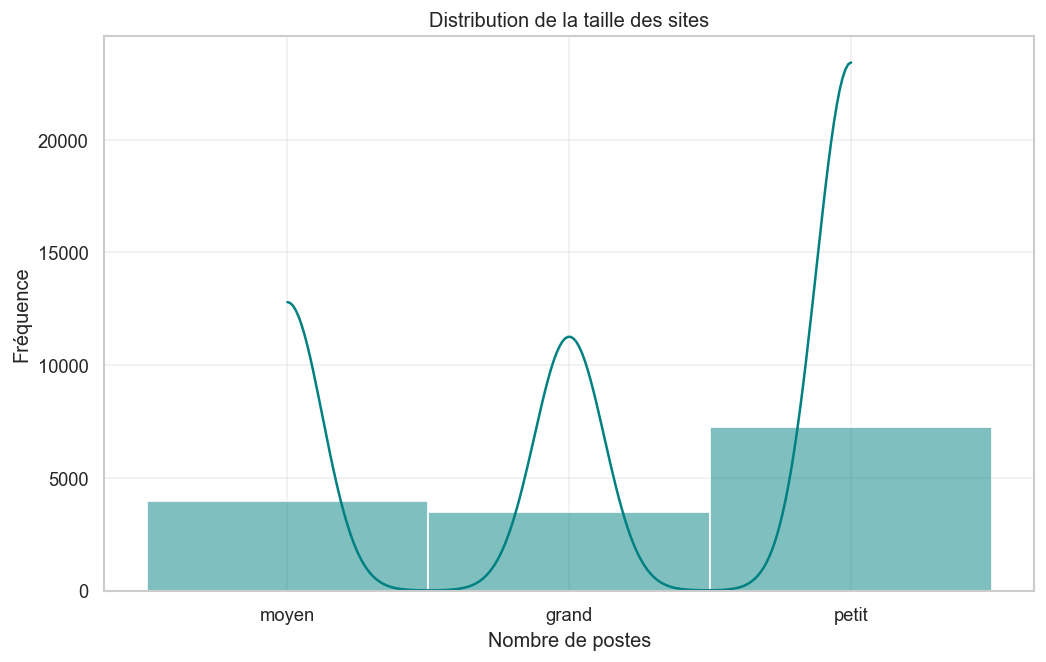

In [255]:
sns.histplot(df["cat_taille_o"], bins=20, kde=True, color="teal")

plt.title("Distribution de la taille des sites")
plt.xlabel("Nombre de postes")
plt.ylabel("Fréquence")
plt.show()

* on constate que la plupart des sites qui ont entre 4 et 10 postes ont le plus d'installations

### 5.6 Distribution des versions de produits 

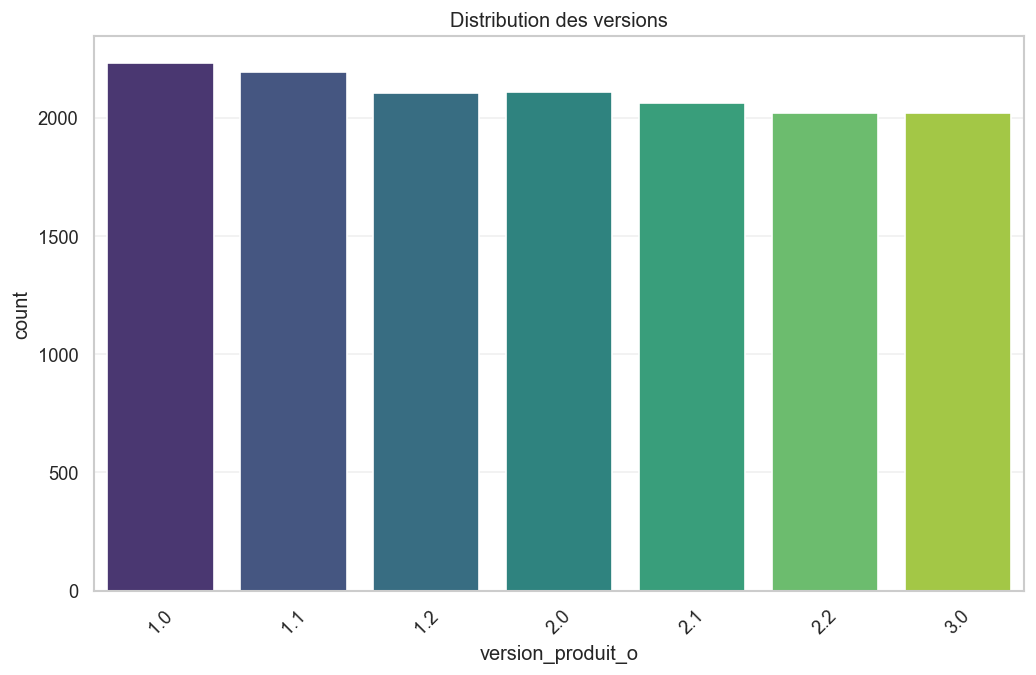

In [256]:
sns.countplot(data=df, x="version_produit_o", palette="viridis")
plt.title("Distribution des versions")
plt.xticks(rotation=45)
plt.show()

- on trouve que les versions 1.0 et 1.1 sont les plus dominantes

In [257]:
top_versions = df["version_produit_o"].value_counts().sort_values(ascending=False).head(2)
print(top_versions)
versions_obsoletes = df["version_produit_o"].value_counts().sort_values().head(2)
print(versions_obsoletes)

version_produit_o
1.0    2233
1.1    2192
Name: count, dtype: int64
version_produit_o
3.0    2018
2.2    2021
Name: count, dtype: int64


In [258]:
import plotly.express as px

fig = px.pie(
    df,
    names="client_risque",
    title="Répartition des clients à risque",
    color="client_risque",
    color_discrete_map={0: "green", 1: "red"}
)

fig.show()


In [259]:
fig = px.histogram(
    df,
    x="client_risque",
    nbins=2,
    title="Distribution du score de risque client",
    color="client_risque"
)

fig.show()


In [260]:
version_risque = df.groupby("version_produit_o")["client_risque"].mean().reset_index()
version_risque.columns = ["version_produit_o", "taux_risque"]
version_max_risque = version_risque.sort_values("taux_risque", ascending=False).head(1)
print(version_max_risque)
fig = px.bar(
    version_risque,
    x="version_produit_o",
    y="taux_risque",
    title="Taux de risque par version produit",
    color="taux_risque",
    color_continuous_scale="Reds"
)

fig.show()


   version_produit_o  taux_risque
0                1.0     0.613077


In [261]:
produit_risque = df.groupby("Nom_produit_o")["client_risque"].mean().reset_index()
produit_risque.columns = ["Nom_produit_o", "taux_risque"]
fig = px.bar(
    produit_risque,
    x="Nom_produit_o",
    y="taux_risque",
    title="Taux de risque par produit",
    color="taux_risque",
    color_continuous_scale="Reds"
)

fig.show()


In [262]:
kpi_risque = {
    "taux_clients_risque": df["client_risque"].mean(),
}
kpi_risque

{'taux_clients_risque': np.float64(0.6032564450474899)}

In [263]:
risque_vs_reussite = df.groupby("client_risque")["installation_reussie_encoded"].mean().reset_index()

fig = px.bar(
    risque_vs_reussite,
    x="client_risque",
    y="installation_reussie_encoded",
    title="Impact du risque sur la réussite",
    color="client_risque"
)
fig.show()

In [264]:
kpi_problemes = {
    "taux_pb_reseau": df["pb_reseau"].mean(),
    "taux_pb_config": df["pb_configuration"].mean(),
    "taux_pb_materiel": df["pb_materiel"].mean(),
    "taux_pb_version": df["pb_version"].mean(),
    "taux_pb_aucun": df["pb_aucun"].mean()
}
kpi_problemes

{'taux_pb_reseau': np.float64(0.1069877883310719),
 'taux_pb_config': np.float64(0.13331071913161466),
 'taux_pb_materiel': np.float64(0.22333785617367707),
 'taux_pb_version': np.float64(0.587652645861601),
 'taux_pb_aucun': np.float64(0.0042740841248303935)}

In [265]:
pb_cols = ["pb_reseau", "pb_configuration", "pb_materiel", "pb_version", "pb_aucun"]

pb_data = df[pb_cols].mean().reset_index()
pb_data.columns = ["type_probleme", "frequence"]

fig = px.bar(
    pb_data,
    x="type_probleme",
    y="frequence",
    title="Fréquence des types de problèmes",
    color="frequence"
)
fig.show()

In [266]:
kpi_cat = df.groupby("cat_debit_o").agg({
    "installation_reussie_encoded": "mean",
    "client_satisfait_encoded": "mean",
    "client_risque": "mean"
}).reset_index()
kpi_cat

,cat_debit_o,installation_reussie_encoded,client_satisfait_encoded,client_risque
0,bon,0.596393,0.561135,0.500045
1,faible,0.162378,0.062112,0.996451
2,moyen,0.158527,0.079070,0.872868


In [267]:
fig = px.bar(
    kpi_cat,
    x="cat_debit_o",
    y="installation_reussie_encoded",
    color="cat_debit_o",
    title="Impact du débit sur la réussite"
)
fig.show()

In [268]:
kpi_upgrade = df.groupby("upgrade").agg({
    "installation_reussie_encoded": "mean",
    "client_risque": "mean",
    "Duree_installation_minutes": "mean"
}).reset_index()

In [269]:
fig = px.bar(
    kpi_upgrade,
    x="upgrade",
    y="installation_reussie_encoded",
    color="upgrade",
    title="Impact des versions récentes (upgrade)"
)
fig.show()

In [270]:
os_perf = df.groupby("Systeme_exploitation_poste").agg({
    "installation_reussie_encoded": "mean",
    "os_enc": "mean"
}).reset_index()
os_perf

,Systeme_exploitation_poste,installation_reussie_encoded,os_enc
0,Win10,0.558060,0.558060
1,Win11,0.580788,0.580788
2,Win7,0.221703,0.221703
3,Win8,0.148285,0.148285
4,Windows 2008 Server,0.131256,0.131256
5,Windows 2012 Server,0.168083,0.168083
6,Windows server 2016,0.632556,0.632556
7,Windows server 2019,0.691307,0.691307
8,Windows server 2022,0.673067,0.673067
9,WindowsXP,0.123077,0.123077


### 5.3 cause:

In [271]:
kpi_causes = {
    "pb_reseau": df[df["client_risque"] == 1]["pb_reseau"].mean(),
    "pb_configuration": df[df["client_risque"] == 1]["pb_configuration"].mean(),
    "pb_materiel": df[df["client_risque"] == 1]["pb_materiel"].mean(),
    "pb_version": df[df["client_risque"] == 1]["pb_version"].mean(),
    "pb_aucun": df[df["client_risque"] == 1]["pb_aucun"].mean()
}
kpi_causes

{'pb_reseau': np.float64(0.16295546558704455),
 'pb_configuration': np.float64(0.16902834008097167),
 'pb_materiel': np.float64(0.2802519118308592),
 'pb_version': np.float64(0.45051731893837155),
 'pb_aucun': np.float64(0.006072874493927126)}

In [272]:
df_grouped_duree = df.groupby("pb_reseau").agg({
    "Duree_installation_minutes": "mean"
}).reset_index()

fig = px.bar(
    df_grouped_duree,
    x="pb_reseau",
    y="Duree_installation_minutes",
    title="Impact problème réseau sur durée", 
    color="pb_reseau",
    color_discrete_map={0: "green", 1: "red"}
)
fig.show()

cause:

In [273]:
df.columns

Index(['version_produit', 'date_installation', 'Gouvernorat', 'Id_Client',
       'Systeme_exploitation_poste', 'installation_reussie',
       'nombre_essais_installation', 'client_a_reclame',
       'nombre_reclamations_client', 'client_satisfait', 'Remarques',
       'Technicien_ID', 'Duree_installation_minutes', 'Debit_reseau_Mbps',
       'Taille_site_postes', 'Tentative_installation_weekend',
       'Version_precedente', 'pb_reseau', 'pb_configuration', 'pb_materiel',
       'pb_version', 'pb_aucun', 'annee', 'jour_semaine', 'mois', 'upgrade',
       'score_risque', 'client_risque', 'installation_reussie_encoded',
       'client_satisfait_encoded', 'client_a_reclame_encoded',
       'Tentative_installation_weekend_encoded', 'version_produit_o',
       'version_produit_encoded', 'os_enc', 'Nom_produit_o', 'Type_client_o',
       'Mode_installation_o', 'cat_taille_o', 'cat_debit_o',
       'zone_urbanisation_o', 'Nom_produit_INSAF', 'Nom_produit_MADANIA',
       'Nom_produit_MAKATIB

In [274]:
variables = [
    "zone_urbanisation_o", "cat_debit_o", "cat_taille_o",
    "Mode_installation_o", "Type_client_o", "Nom_produit_o", "upgrade", "mois", "annee", "pb_reseau", "pb_configuration",
    "pb_materiel", "pb_version","pb_aucun",
    "os_enc",
    "Duree_installation_minutes","version_produit","nombre_reclamations_client"
]

results = []

for var in variables:
    grouped = df.groupby(var)["client_risque"].mean().reset_index()
    
    grouped = grouped.rename(columns={
        var: "modalite",
        "client_risque": "taux_risque"
    })
    
    grouped["variable"] = var
    
    grouped["modalite"] = grouped["modalite"].astype(str)
    
    results.append(grouped)

df_risk_analysis = pd.concat(results, ignore_index=True)

df_risk_analysis.head(50)

,modalite,taux_risque,variable
0,metropolitaine,0.530032,zone_urbanisation_o
1,mixte,0.572022,zone_urbanisation_o
2,rurale,0.764836,zone_urbanisation_o
3,bon,0.500045,cat_debit_o
4,faible,0.996451,cat_debit_o
5,moyen,0.872868,cat_debit_o
6,grand,0.734840,cat_taille_o
7,moyen,0.589376,cat_taille_o
8,petit,0.547580,cat_taille_o
9,Technicien_sur_site,0.616375,Mode_installation_o


In [275]:
df_risk_analysis = df_risk_analysis.copy()

# convertir toutes les colonnes interval en string
for col in df_risk_analysis.columns:
    if df_risk_analysis[col].dtype.name == "category":
        df_risk_analysis[col] = df_risk_analysis[col].astype(str)

In [276]:
for var in df_risk_analysis["variable"].unique():
    
    df_var = (
        df_risk_analysis[df_risk_analysis["variable"] == var]
        .sort_values("taux_risque", ascending=False)
        .head(5)   # top 5 seulement
    )

    fig = px.bar(
        df_var,
        x="modalite",
        y="taux_risque",
        color="taux_risque",
        title=f"Top facteurs de risque - {var}"
    )

    fig.update_layout()

    fig.show()

In [277]:
importance_var = (
    df_risk_analysis
    .groupby("variable")["taux_risque"]
    .agg(["max", "min"]))
importance_var["impact"] = importance_var["max"] - importance_var["min"]
importance_var = importance_var.sort_values("impact", ascending=False)
top5 = importance_var.head(5).reset_index()
top5["label"] = "max=" + top5["max"].round(2).astype(str)
fig = px.bar(
    top5,
    x="impact",
    y="variable",
    orientation="h",
    text="label",
    color="impact",
    title="Top 5 facteurs influençant le risque client"
    )
fig.show()

In [278]:
df_grouped_version = df.groupby("version_produit_o")["client_risque"].mean().reset_index()

fig = px.bar(
    df_grouped_version,
    x="version_produit_o",
    y="client_risque",
    color="client_risque",
    title="Risque par version produit"
)
fig.show()

In [279]:
df_grouped_produit = df.groupby("Nom_produit_o")["client_risque"].mean().reset_index()

fig = px.bar(
    df_grouped_produit,
    x="Nom_produit_o",
    y="client_risque",
    color="client_risque",
    title="Risque par produit"
)
fig.show()

### 5.4 Features selection

In [280]:
df["mois"] = pd.to_datetime(df["mois"], format="%Y-%m")
df["mois_num"] = df["mois"].dt.month

df_sad = df.copy()

var_a_effacer =[       
       'date_installation', 'Gouvernorat', 'Id_Client', 'installation_reussie',
       'client_a_reclame', 'client_satisfait', 'Remarques',
       'Technicien_ID', 'Tentative_installation_weekend','version_produit_encoded'
       'Version_precedente', 'version_produit_o', 'taux_reussite', 'temps_par_essai',
       'efficacite_installation', 'complexite_site', 'complexite_installation',
       'score_risque', 'nombre_reclamations','os_enc', 'Nom_produit_o',
       'Type_client_o', 'Mode_installation_o', 'cat_taille_o', 'cat_debit_o',
       'zone_urbanisation_o',"mois",'cat_debit_moyen',
       'cat_taille_moyen', 'cat_taille_petit', 'cat_debit_faible'
       ]

df = df.drop(columns=var_a_effacer, errors='ignore')

In [281]:
df_sad.columns

Index(['version_produit', 'date_installation', 'Gouvernorat', 'Id_Client',
       'Systeme_exploitation_poste', 'installation_reussie',
       'nombre_essais_installation', 'client_a_reclame',
       'nombre_reclamations_client', 'client_satisfait', 'Remarques',
       'Technicien_ID', 'Duree_installation_minutes', 'Debit_reseau_Mbps',
       'Taille_site_postes', 'Tentative_installation_weekend',
       'Version_precedente', 'pb_reseau', 'pb_configuration', 'pb_materiel',
       'pb_version', 'pb_aucun', 'annee', 'jour_semaine', 'mois', 'upgrade',
       'score_risque', 'client_risque', 'installation_reussie_encoded',
       'client_satisfait_encoded', 'client_a_reclame_encoded',
       'Tentative_installation_weekend_encoded', 'version_produit_o',
       'version_produit_encoded', 'os_enc', 'Nom_produit_o', 'Type_client_o',
       'Mode_installation_o', 'cat_taille_o', 'cat_debit_o',
       'zone_urbanisation_o', 'Nom_produit_INSAF', 'Nom_produit_MADANIA',
       'Nom_produit_MAKATIB

## 6. Modelisation

In [282]:
from category_encoders import TargetEncoder

def target_encoding(X_train, X_test, df, target):

    y_train = df.loc[X_train.index, target]
    y_test  = df.loc[X_test.index, target]

    X_tr = X_train.copy()
    X_te = X_test.copy()

    # colonnes à encoder
    cols = ["Systeme_exploitation_poste", "version_produit"]

    encoder = TargetEncoder(cols=cols)

    X_tr[cols] = encoder.fit_transform(X_tr[cols], y_train)
    X_te[cols] = encoder.transform(X_te[cols])
    
    # supprimer anciennes colonnes
    X_tr = X_tr.drop(columns=["Systeme_exploitation_poste", "version_produit"], errors='ignore')
    X_te = X_te.drop(columns=["Systeme_exploitation_poste", "version_produit"], errors='ignore')

    return X_tr, X_te, y_train, y_test

In [283]:
def feature_selection(X, y, task="classification", k=15, seuil=0.01):

    if task == "classification":
        mi = mutual_info_classif(X, y, random_state=42)
    else:
        mi = mutual_info_regression(X, y, random_state=42)

    mi_df = pd.DataFrame({
        "feature": X.columns,
        "MI": mi
    }).sort_values("MI", ascending=False)

    retenues  = mi_df[mi_df["MI"] >= seuil].head(k)

    print(f"\n Features RETENUES (MI >= {seuil}) : {len(retenues)}")
    print(retenues.to_string(index=False))

    features_retenues = retenues["feature"].tolist()
    return features_retenues, mi_df

In [284]:
def standardiser(X_train, X_test, cols_continues):
    cols = [c for c in cols_continues if c in X_train.columns]
    scaler = StandardScaler()
    X_train = X_train.copy()
    X_test  = X_test.copy()
    X_train[cols] = scaler.fit_transform(X_train[cols])
    X_test[cols]  = scaler.transform(X_test[cols])
    return X_train, X_test, scaler


In [285]:
def evaluer_classifieurs(modeles, X_train, X_test, y_train, y_test):
    resultats = []
    for nom, modele in modeles.items():
        modele.fit(X_train, y_train)
        y_pred  = modele.predict(X_test)
        y_proba = modele.predict_proba(X_test)[:, 1] if hasattr(modele, "predict_proba") else None

        cv = cross_val_score(modele, X_train, y_train,
                             cv=StratifiedKFold(5), scoring="f1").mean()
        resultats.append({
            "Modèle":    nom,
            "Accuracy":  accuracy_score(y_test, y_pred),
            "F1-Score":  f1_score(y_test, y_pred),
            "ROC-AUC":   roc_auc_score(y_test, y_proba) if y_proba is not None else None,
            "CV F1":     cv
        })
    return pd.DataFrame(resultats).sort_values("F1-Score", ascending=False)

In [286]:
def evaluer_regresseurs(modeles, X_train, X_test, y_train, y_test):
    resultats = []
    for nom, modele in modeles.items():
        modele.fit(X_train, y_train)
        y_pred = modele.predict(X_test)

        cv = cross_val_score(modele, X_train, y_train,
                             cv=KFold(5), scoring="r2").mean()
        resultats.append({
            "Modèle": nom,
            "R²":     r2_score(y_test, y_pred),
            "MAE":    mean_absolute_error(y_test, y_pred),
            "RMSE":   np.sqrt(mean_squared_error(y_test, y_pred)),
            "CV R²":  cv
        })
    return pd.DataFrame(resultats).sort_values("R²", ascending=False)

In [287]:
def plot_confusion(modele, X_test, y_test, titre):
    cm = confusion_matrix(y_test, modele.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix - {titre}")
    plt.xlabel("Prédit"); plt.ylabel("Réel")
    plt.tight_layout(); plt.show()

In [288]:
def plot_resultats_regression(modele, X_test, y_test, titre):
    y_pred = modele.predict(X_test)

    plt.figure(figsize=(7, 6))

    plt.scatter(
        y_test,
        y_pred,
        alpha=0.5,
        color="steelblue",
        edgecolors="white",
        s=40
    )

    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())

    plt.plot(
        [min_val, max_val],
        [min_val, max_val],
        color="red",
        linestyle="--",
        linewidth=2,
        label="Prédiction parfaite"
    )

    plt.xlabel("Valeurs réelles")
    plt.ylabel("Valeurs prédites")
    plt.title(f"Réel vs Prédit - {titre}")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


In [289]:
CLASSIFIEURS = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree":       DecisionTreeClassifier(random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=42),
    "XGBoost":             XGBClassifier(eval_metric="logloss", random_state=42),
    "KNN":                 KNeighborsClassifier(),
    "SVM":                 SVC(probability=True, random_state=42),
}

REGRESSEURS = {
    "Linear Regression":   LinearRegression(),
    "Ridge":               Ridge(random_state=42),
    "Lasso":               Lasso(random_state=42),
    "Decision Tree":       DecisionTreeRegressor(random_state=42),
    "Random Forest":       RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting":   GradientBoostingRegressor(random_state=42),
    "XGBoost":             XGBRegressor(random_state=42),
}


In [290]:
targets = [
    "installation_reussie_encoded",
    "client_satisfait_encoded",
    "Duree_installation_minutes",
    "client_risque",
    "client_a_reclame_encoded" 
]

X = df.drop(columns=targets)

X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

   MODÈLE 1 : client_risque

 Features RETENUES (MI >= 0.01) : 11
                   feature       MI
nombre_essais_installation 0.143681
nombre_reclamations_client 0.100757
         Debit_reseau_Mbps 0.099608
                pb_version 0.065012
                 pb_reseau 0.031277
        Taille_site_postes 0.029400
  zone_urbanisation_rurale 0.023170
               pb_materiel 0.013500
     Type_client_Ministère 0.012624
          pb_configuration 0.011981
         Nom_produit_INSAF 0.010834

 Evaluation des modèles :                 Modèle  Accuracy  F1-Score   ROC-AUC     CV F1
3    Gradient Boosting  0.843284  0.871237  0.923313  0.866578
4              XGBoost  0.830733  0.861964  0.920851  0.853460
0  Logistic Regression  0.816486  0.853427  0.892573  0.852018
2        Random Forest  0.814450  0.850096  0.906873  0.846786
6                  SVM  0.809362  0.848681  0.887878  0.834490
1        Decision Tree  0.788670  0.826511  0.779098  0.823162
5                  KNN  0.784261  

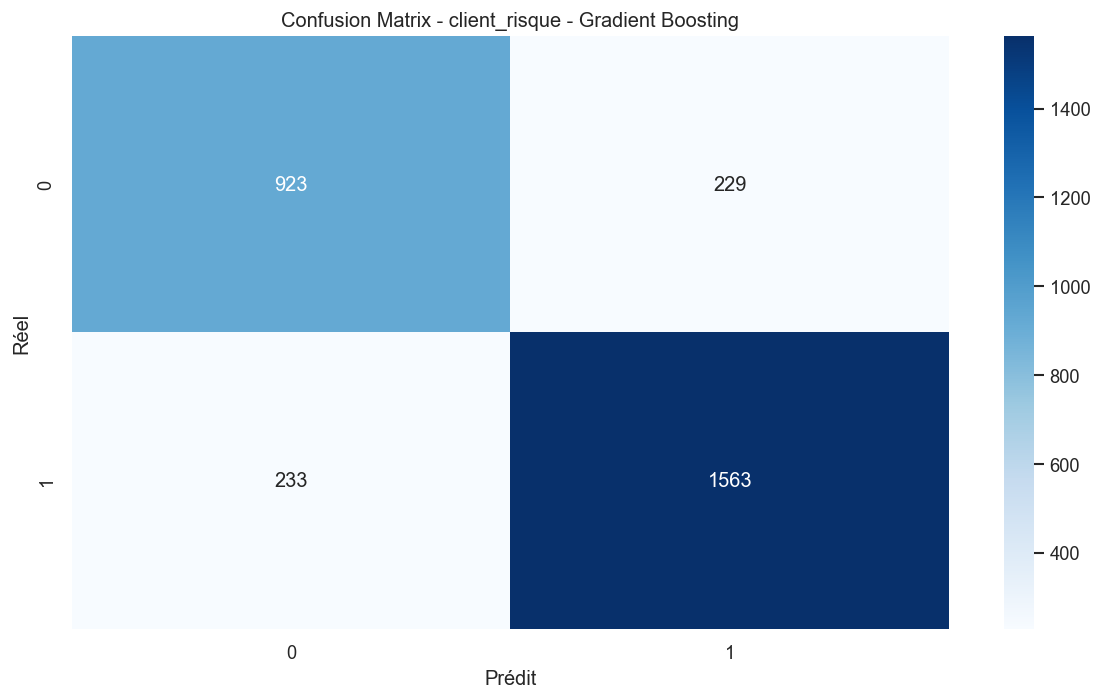

In [291]:
print("   MODÈLE 1 : client_risque")

y1 = df["client_risque"]

X1_train, X1_test = X_train.copy(), X_test.copy()

X1_train, X1_test, y1_train, y1_test = target_encoding(
    X1_train, X1_test, df, "client_risque"
)

features1, mi_df = feature_selection(
    X1_train, y1_train,
    task="classification",
    k=15
)

X1_train = X1_train[features1]
X1_test  = X1_test[features1]

resultats1 = evaluer_classifieurs(
    CLASSIFIEURS,
    X1_train, X1_test,
    y1_train, y1_test
)

print(f"\n Evaluation des modèles : {resultats1}")

meilleur1_nom = resultats1.iloc[0]["Modèle"]
meilleur1 = CLASSIFIEURS[meilleur1_nom]
meilleur1.fit(X1_train, y1_train)
print(f"\n Meilleur modèle : {meilleur1_nom}")
print(f"\nClassification report : ")
print(classification_report(y1_test, meilleur1.predict(X1_test)))
plot_confusion(meilleur1, X1_test, y1_test, f"client_risque - {meilleur1_nom}")

   MODÈLE 2 : installation_reussie

 Features RETENUES (MI >= 0.01) : 8
                   feature       MI
nombre_reclamations_client 0.329014
nombre_essais_installation 0.300131
         Debit_reseau_Mbps 0.086636
                pb_version 0.074535
        Taille_site_postes 0.033266
                 pb_reseau 0.027860
          pb_configuration 0.024708
               pb_materiel 0.012935

 Evaluation des modèles :                 Modèle  Accuracy  F1-Score   ROC-AUC     CV F1
3    Gradient Boosting  0.876526  0.864583  0.894847  0.872753
4              XGBoost  0.874152  0.862542  0.893068  0.869594
6                  SVM  0.871777  0.858002  0.882727  0.868383
0  Logistic Regression  0.868385  0.856296  0.883720  0.868050
5                  KNN  0.857870  0.846126  0.881849  0.853468
2        Random Forest  0.848711  0.836270  0.886845  0.844222
1        Decision Tree  0.800204  0.792386  0.799775  0.793657

 Meilleur modèle : Gradient Boosting

Classification report : 
         

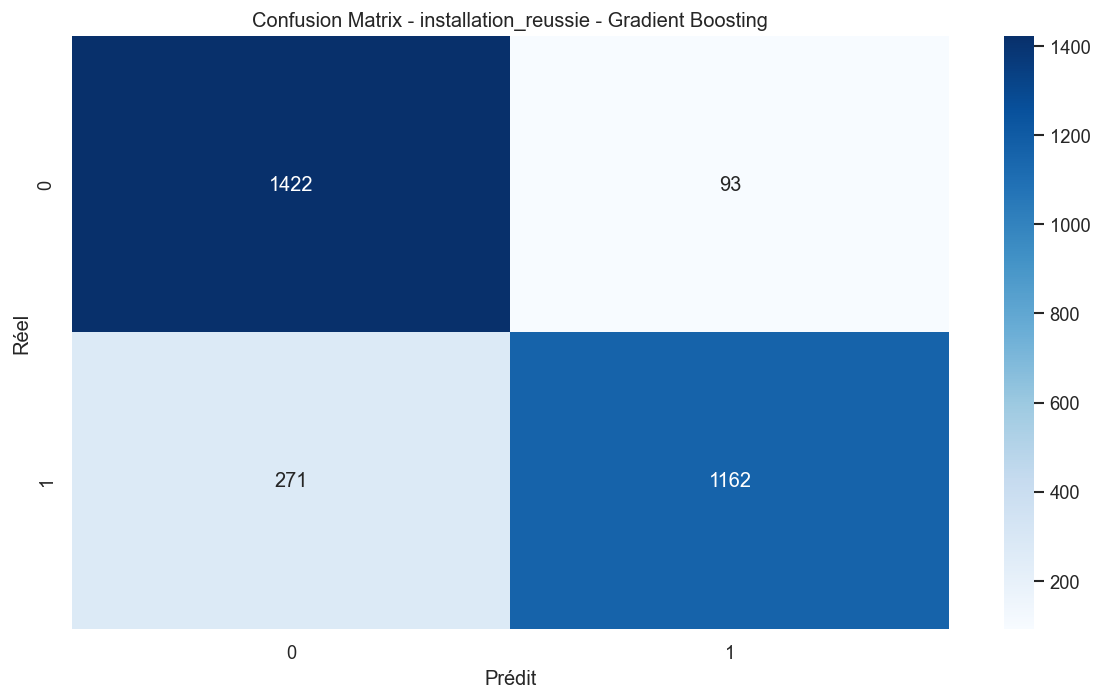

In [292]:
print("   MODÈLE 2 : installation_reussie")

y2 = df["installation_reussie_encoded"]

X2_train, X2_test = X_train.copy(), X_test.copy()

X2_train, X2_test, y2_train, y2_test = target_encoding(
    X2_train, X2_test, df, "installation_reussie_encoded"
)

features2, mi_df = feature_selection(
    X2_train, y2_train,
    task="classification",
    k=15
)

X2_train = X2_train[features2]
X2_test  = X2_test[features2]

resultats2 = evaluer_classifieurs(
    CLASSIFIEURS,
    X2_train, X2_test,
    y2_train, y2_test
)

print(f"\n Evaluation des modèles : {resultats2}")

meilleur2_nom = resultats2.iloc[0]["Modèle"]
meilleur2 = CLASSIFIEURS[meilleur2_nom]
meilleur2.fit(X2_train, y2_train)
print(f"\n Meilleur modèle : {meilleur2_nom}")
print(f"\nClassification report : ")
print(classification_report(y2_test, meilleur2.predict(X2_test)))
plot_confusion(meilleur2, X2_test, y2_test, f"installation_reussie - {meilleur2_nom}")

   MODÈLE 3 : client_satisfait

 Features RETENUES (MI >= 0.01) : 8
                   feature       MI
nombre_reclamations_client 0.415313
nombre_essais_installation 0.395558
         Debit_reseau_Mbps 0.118268
                pb_version 0.101317
        Taille_site_postes 0.048557
                 pb_reseau 0.036664
          pb_configuration 0.035498
               pb_materiel 0.020860

 Evaluation des modèles :                 Modèle  Accuracy  F1-Score   ROC-AUC     CV F1
4              XGBoost  0.934871  0.923200  0.946861  0.929332
3    Gradient Boosting  0.934193  0.922088  0.947159  0.929486
6                  SVM  0.928765  0.915391  0.934413  0.922573
0  Logistic Regression  0.924695  0.910628  0.937742  0.920710
5                  KNN  0.924016  0.910256  0.932791  0.912381
2        Random Forest  0.924016  0.910112  0.943859  0.918488
1        Decision Tree  0.889417  0.870635  0.885505  0.876115

 Meilleur modèle : XGBoost

 Callsification report : 
              precisio

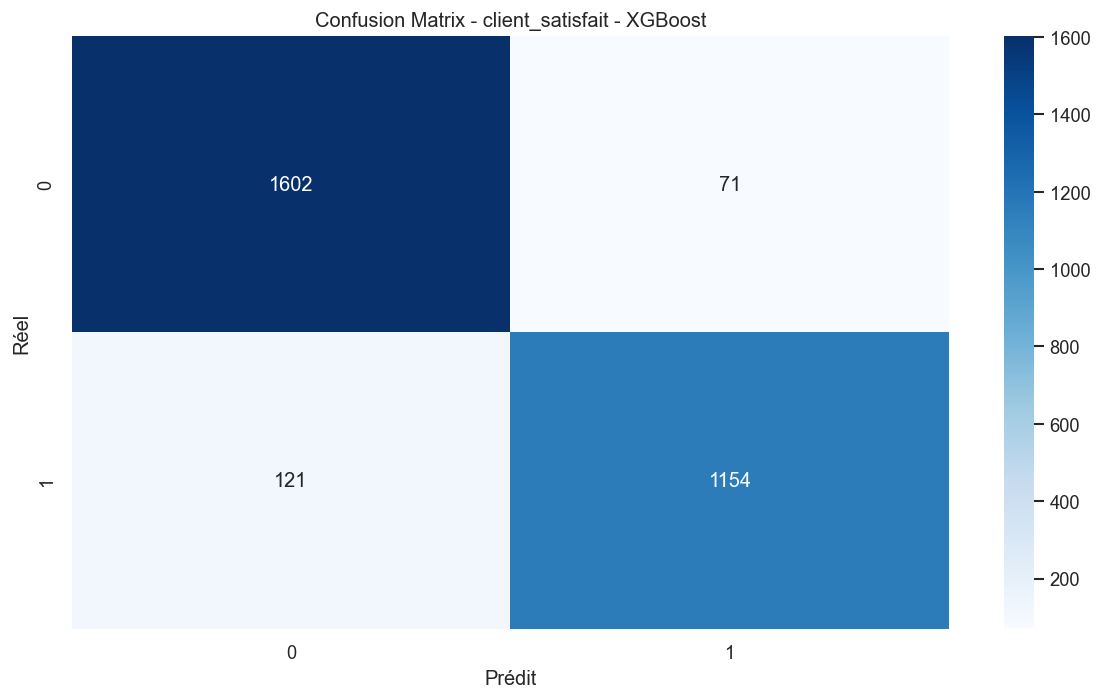

In [293]:
print("   MODÈLE 3 : client_satisfait")

y3 = df["client_satisfait_encoded"]

X3_train, X3_test = X_train.copy(), X_test.copy()

X3_train, X3_test, y3_train, y3_test = target_encoding(
    X3_train, X3_test, df, "client_satisfait_encoded"
)

features3, mi_df = feature_selection(
    X3_train, y3_train,
    task="classification",
    k=15
)

X3_train = X3_train[features3]
X3_test  = X3_test[features3]

resultats3 = evaluer_classifieurs(
    CLASSIFIEURS,
    X3_train, X3_test,
    y3_train, y3_test
)

print(f"\n Evaluation des modèles : {resultats3}")

meilleur3_nom = resultats3.iloc[0]["Modèle"]
meilleur3 = CLASSIFIEURS[meilleur3_nom]
meilleur3.fit(X3_train, y3_train)
print(f"\n Meilleur modèle : {meilleur3_nom}")
print(f"\n Callsification report : ")
print(classification_report(y3_test, meilleur3.predict(X3_test)))
plot_confusion(meilleur3, X3_test, y3_test, f"client_satisfait - {meilleur3_nom}")

   MODÈLE 4 : client_a_reclame



 Features RETENUES (MI >= 0.01) : 8
                   feature       MI
nombre_reclamations_client 0.542483
nombre_essais_installation 0.531262
         Debit_reseau_Mbps 0.159049
                pb_version 0.124724
        Taille_site_postes 0.065702
          pb_configuration 0.047148
                 pb_reseau 0.047138
               pb_materiel 0.028242

 Evaluation des modèles :                 Modèle  Accuracy  F1-Score   ROC-AUC     CV F1
3    Gradient Boosting  0.983039  0.985632  0.995582  0.982896
4              XGBoost  0.981343  0.984218  0.994807  0.981221
2        Random Forest  0.979308  0.982526  0.994348  0.980222
0  Logistic Regression  0.977951  0.981316  0.994918  0.979819
6                  SVM  0.976594  0.980167  0.992900  0.978022
5                  KNN  0.972863  0.976972  0.986574  0.972503
1        Decision Tree  0.968114  0.973219  0.965865  0.972631

 Meilleur modèle : Gradient Boosting

 Callsification report : 
              precision    recall  f1-score

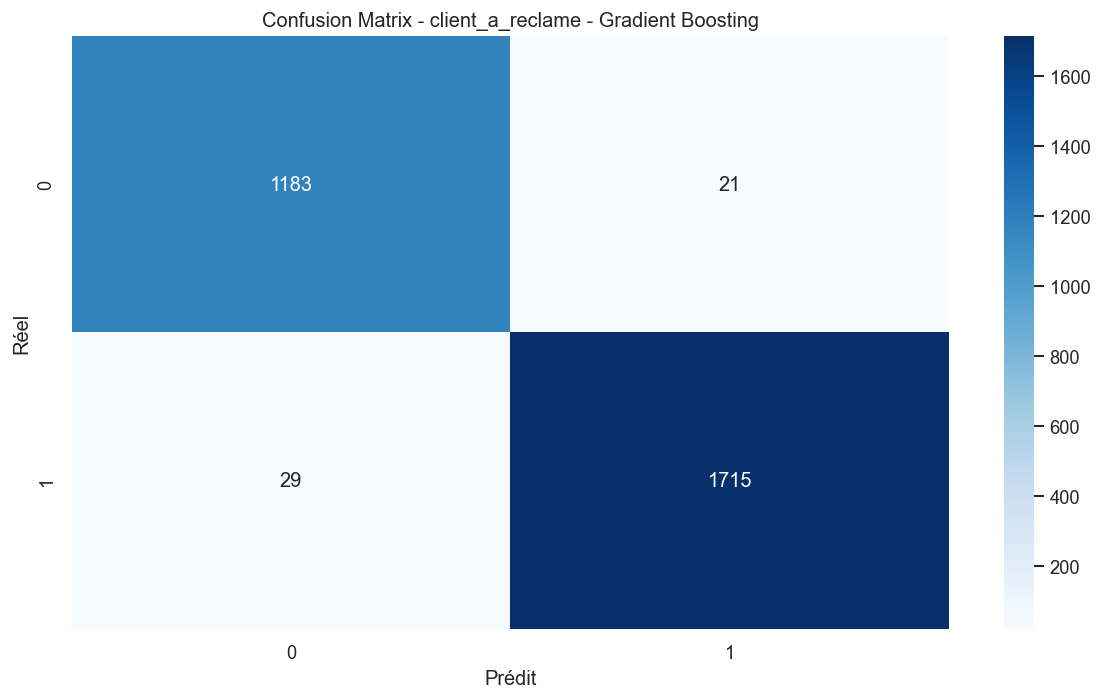

In [294]:
print("   MODÈLE 4 : client_a_reclame")

y4 = df["client_a_reclame_encoded"]

X4_train, X4_test = X_train.copy(), X_test.copy()

X4_train, X4_test, y4_train, y4_test = target_encoding(
    X4_train, X4_test, df, "client_a_reclame_encoded"
)

features4, mi_df = feature_selection(
    X4_train, y4_train,
    task="classification",
    k=15
)

X4_train = X4_train[features4]
X4_test  = X4_test[features4]

resultats4 = evaluer_classifieurs(
    CLASSIFIEURS,
    X4_train, X4_test,
    y4_train, y4_test
)

print(f"\n Evaluation des modèles : {resultats4}")

meilleur4_nom = resultats4.iloc[0]["Modèle"]
meilleur4 = CLASSIFIEURS[meilleur4_nom]
meilleur4.fit(X4_train, y4_train)
print(f"\n Meilleur modèle : {meilleur4_nom}")
print(f"\n Callsification report : ")
print(classification_report(y4_test, meilleur4.predict(X4_test)))
plot_confusion(meilleur4, X4_test, y4_test, f"client_a_reclame - {meilleur4_nom}")

   MODÈLE 5 : durée installation

 Features RETENUES (MI >= 0.01) : 12
                          feature       MI
       nombre_essais_installation 0.418226
       nombre_reclamations_client 0.340874
                Debit_reseau_Mbps 0.300734
                       pb_version 0.085184
                        pb_reseau 0.083688
               Taille_site_postes 0.049509
                 pb_configuration 0.029716
            Type_client_Ministère 0.019273
                      pb_materiel 0.019227
Mode_installation_Télémaintenance 0.016534
                  Type_client_EPA 0.015687
                            annee 0.013511

 Evaluation des modèles : 
              Modèle        R²        MAE       RMSE     CV R²
5  Gradient Boosting  0.757402  17.056562  21.434094  0.754965
4      Random Forest  0.737331  17.492762  22.303135  0.733291
6            XGBoost  0.735523  17.685562  22.379729  0.726482
1              Ridge  0.725941  17.997210  22.781564  0.721336
0  Linear Regression  0.725

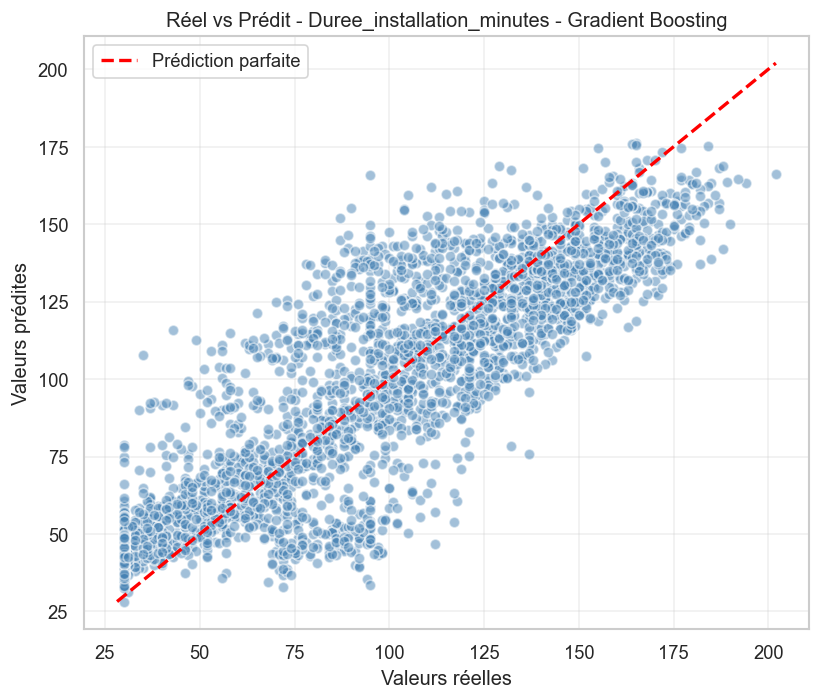


Meilleur modèle : Gradient Boosting
R²   : 0.757
MAE  : 17.06 min
RMSE : 21.43 min


In [295]:
print("   MODÈLE 5 : durée installation")

y5 = df["Duree_installation_minutes"]

X5_train, X5_test = X_train.copy(), X_test.copy()

X5_train, X5_test, y5_train, y5_test = target_encoding(
    X5_train, X5_test, df, "Duree_installation_minutes"
)

features5, mi_df = feature_selection(
    X5_train,
    y5_train,   
    task="regression",
    k=15
)

X5_train = X5_train[features5]
X5_test  = X5_test[features5]

resultats5 = evaluer_regresseurs(
    REGRESSEURS,
    X5_train, X5_test,
    y5_train,
    y5_test
)

print(f"\n Evaluation des modèles : \n{resultats5}")

meilleur5_nom = resultats5.iloc[0]["Modèle"]
meilleur5 = REGRESSEURS[meilleur5_nom]
meilleur5.fit(X5_train, y5_train)
plot_resultats_regression(meilleur5, X5_test, y5_test,
                          f"Duree_installation_minutes - {meilleur5_nom}")
print(f"\nMeilleur modèle : {meilleur5_nom}")
y5_pred = meilleur5.predict(X5_test)
print(f"R²   : {r2_score(y5_test, y5_pred):.3f}")
print(f"MAE  : {mean_absolute_error(y5_test, y5_pred):.2f} min")
print(f"RMSE : {np.sqrt(mean_squared_error(y5_test, y5_pred)):.2f} min")

In [296]:
"""print("\n" + "=" * 60)
print("   SYNTHÈSE FINALE")
print("=" * 60)

synthese = pd.DataFrame([
    {"Cible": "client_risque",              "Type": "Classification",
     "Meilleur modèle": meilleur1_nom,
     "F1": resultats1.iloc[0]["F1-Score"],
     "ROC-AUC": resultats1.iloc[0]["ROC-AUC"]},

    {"Cible": "installation_reussie",       "Type": "Classification",
     "Meilleur modèle": meilleur2_nom,
     "F1": resultats2.iloc[0]["F1-Score"],
     "ROC-AUC": resultats2.iloc[0]["ROC-AUC"]},

    {"Cible": "client_satisfait",           "Type": "Classification",
     "Meilleur modèle": meilleur3_nom,
     "F1": resultats3.iloc[0]["F1-Score"],
     "ROC-AUC": resultats3.iloc[0]["ROC-AUC"]},
    
    {"Cible": "client_a_reclame",           "Type": "Classification",
     "Meilleur modèle": meilleur4_nom,
     "F1": resultats4.iloc[0]["F1-Score"],
     "ROC-AUC": resultats4.iloc[0]["ROC-AUC"]},

    {"Cible": "Duree_installation_minutes", "Type": "Régression",
     "Meilleur modèle": meilleur5_nom,
     "R²": resultats5.iloc[0]["R²"],
     "RMSE": resultats5.iloc[0]["RMSE"]},
])

print(synthese.to_string(index=False))"""

'print("\n" + "=" * 60)\nprint("   SYNTHÈSE FINALE")\nprint("=" * 60)\n\nsynthese = pd.DataFrame([\n    {"Cible": "client_risque",              "Type": "Classification",\n     "Meilleur modèle": meilleur1_nom,\n     "F1": resultats1.iloc[0]["F1-Score"],\n     "ROC-AUC": resultats1.iloc[0]["ROC-AUC"]},\n\n    {"Cible": "installation_reussie",       "Type": "Classification",\n     "Meilleur modèle": meilleur2_nom,\n     "F1": resultats2.iloc[0]["F1-Score"],\n     "ROC-AUC": resultats2.iloc[0]["ROC-AUC"]},\n\n    {"Cible": "client_satisfait",           "Type": "Classification",\n     "Meilleur modèle": meilleur3_nom,\n     "F1": resultats3.iloc[0]["F1-Score"],\n     "ROC-AUC": resultats3.iloc[0]["ROC-AUC"]},\n\n    {"Cible": "client_a_reclame",           "Type": "Classification",\n     "Meilleur modèle": meilleur4_nom,\n     "F1": resultats4.iloc[0]["F1-Score"],\n     "ROC-AUC": resultats4.iloc[0]["ROC-AUC"]},\n\n    {"Cible": "Duree_installation_minutes", "Type": "Régression",\n     "Mei

## Fine-tuning

In [297]:
from sklearn.model_selection import GridSearchCV

def fine_tune_model(model, params, X_train, y_train, scoring):
    grid = GridSearchCV(
        estimator=model,
        param_grid=params,
        cv=5,
        scoring=scoring,
        n_jobs=-1,
        verbose=1
    )

    grid.fit(X_train, y_train)

    print("Best Params:", grid.best_params_)
    print("Best Score :", grid.best_score_)

    return grid.best_estimator_

### Classification

In [298]:
models_classif = {
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=42),
        {
            "n_estimators": [100, 200],
            "learning_rate": [0.05, 0.1],
            "max_depth": [3, 5],
            "subsample": [0.8, 1.0]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {
            "n_estimators": [100, 200],
            "max_depth": [None, 10, 20],
            "min_samples_split": [2, 5],
            "min_samples_leaf": [1, 2]
        }
    ),

    "XGBoost": (
        XGBClassifier(eval_metric="logloss", random_state=42),
        {
            "n_estimators": [100, 200],
            "learning_rate": [0.05, 0.1],
            "max_depth": [3, 5],
            "subsample": [0.8, 1.0],
            "colsample_bytree": [0.8, 1.0]
        }
    )
}

In [ ]:
targets_classif = {
    1: (X1_train, y1_train),
    2: (X2_train, y2_train),
    3: (X3_train, y3_train),
    4: (X4_train, y4_train)
}

best_models_classif_all = {}

for target_id, (X_train_current, y_train_current) in targets_classif.items():

    print("\n" + "="*60)
    print(f" FINE TUNING CLASSIFICATION TARGET {target_id}")
    print("="*60)

    best_models_classif_all[target_id] = {}

    for model_name, (model, params) in models_classif.items():

        print(f"\n--- Fine Tuning {model_name} ---")

        best_model = fine_tune_model(
            model,
            params,
            X_train_current,
            y_train_current,
            scoring="f1"
        )

        best_models_classif_all[target_id][model_name] = best_model


 FINE TUNING CLASSIFICATION TARGET 1

--- Fine Tuning Gradient Boosting ---
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}
Best Score : 0.8680949277743715

--- Fine Tuning Random Forest ---
Fitting 5 folds for each of 24 candidates, totalling 120 fits


### Regréssion

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from xgboost import XGBRegressor

models_reg = {
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=42),
        {
            "n_estimators": [100, 200],
            "learning_rate": [0.05, 0.1],
            "max_depth": [3, 5],
            "subsample": [0.8, 1.0]
        }
    ),

    "Random Forest": (
        RandomForestRegressor(random_state=42),
        {
            "n_estimators": [100, 200],
            "max_depth": [None, 10, 20],
            "min_samples_split": [2, 5],
            "min_samples_leaf": [1, 2]
        }
    ),

    "XGBoost": (
        XGBRegressor(random_state=42),
        {
            "n_estimators": [100, 200],
            "learning_rate": [0.05, 0.1],
            "max_depth": [3, 5],
            "subsample": [0.8, 1.0],
            "colsample_bytree": [0.8, 1.0]
        }
    )
}

In [ ]:
targets_reg = {
    5: (X5_train, y5_train)
}

best_models_reg_all = {}

for target_id, (X_train_current, y_train_current) in targets_reg.items():

    print("\n" + "="*60)
    print(f" FINE TUNING REGRESSION TARGET {target_id}")
    print("="*60)

    best_models_reg_all[target_id] = {}

    for model_name, (model, params) in models_reg.items():

        print(f"\n--- Fine Tuning {model_name} ---")

        best_model = fine_tune_model(
            model,
            params,
            X_train_current,
            y_train_current,
            scoring="r2"
        )

        best_models_reg_all[target_id][model_name] = best_model


 FINE TUNING REGRESSION TARGET 5

--- Fine Tuning Gradient Boosting ---
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100, 'subsample': 0.8}
Best Score : 0.7567590962659438

--- Fine Tuning Random Forest ---
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Params: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
Best Score : 0.7517433291905006

--- Fine Tuning XGBoost ---
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best Params: {'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100, 'subsample': 0.8}
Best Score : 0.7567638874053955


In [ ]:
KNN = {
    "KNN": (
        KNeighborsClassifier(),
        {
            "n_neighbors": [8, 10, 12, 16, 18, 20, 24, 27, 30],
            "weights": ["uniform", "distance"],
            "metric": ["euclidean", "manhattan"]
        }
    )
}

best_extra_classif = {}

for target_name, (X_train_current, y_train_current) in targets_classif.items():

    print("\n" + "="*60)
    print(f" EXTRA FINE TUNING CLASSIFICATION : {target_name}")
    print("="*60)

    best_extra_classif[target_name] = {}

    for model_name, (model, params) in KNN.items():

        print(f"\n--- Fine Tuning {model_name} ---")

        best_model = fine_tune_model(
            model,
            params,
            X_train_current,
            y_train_current,
            scoring="f1"
        )

        best_extra_classif[target_name][model_name] = best_model


 EXTRA FINE TUNING CLASSIFICATION : 1

--- Fine Tuning KNN ---
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Params: {'metric': 'manhattan', 'n_neighbors': 27, 'weights': 'distance'}
Best Score : 0.8361911574893479

 EXTRA FINE TUNING CLASSIFICATION : 2

--- Fine Tuning KNN ---
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Params: {'metric': 'manhattan', 'n_neighbors': 16, 'weights': 'uniform'}
Best Score : 0.8666113757272008

 EXTRA FINE TUNING CLASSIFICATION : 3

--- Fine Tuning KNN ---
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Params: {'metric': 'manhattan', 'n_neighbors': 8, 'weights': 'uniform'}
Best Score : 0.9216965100713539

 EXTRA FINE TUNING CLASSIFICATION : 4

--- Fine Tuning KNN ---
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Params: {'metric': 'manhattan', 'n_neighbors': 12, 'weights': 'distance'}
Best Score : 0.9773390820417809


In [ ]:
SVM = {
    "SVM": (
        SVC(probability=True, random_state=42),
        {
            "C": [0.1, 1, 10],
            "kernel": ["linear", "rbf"],
            "gamma": ["scale", "auto"]
        }
    )
}

best_extra_classif = {}

for target_name, (X_train_current, y_train_current) in targets_classif.items():

    print("\n" + "="*60)
    print(f" EXTRA FINE TUNING CLASSIFICATION : {target_name}")
    print("="*60)

    best_extra_classif[target_name] = {}

    for model_name, (model, params) in SVM.items():

        print(f"\n--- Fine Tuning {model_name} ---")

        best_model = fine_tune_model(
            model,
            params,
            X_train_current,
            y_train_current,
            scoring="f1"
        )

        best_extra_classif[target_name][model_name] = best_model


 EXTRA FINE TUNING CLASSIFICATION : 1

--- Fine Tuning SVM ---
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Params: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best Score : 0.8551619196278555

 EXTRA FINE TUNING CLASSIFICATION : 2

--- Fine Tuning SVM ---
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Params: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Best Score : 0.8683834757273152

 EXTRA FINE TUNING CLASSIFICATION : 3

--- Fine Tuning SVM ---
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Params: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best Score : 0.9236165322010331

 EXTRA FINE TUNING CLASSIFICATION : 4

--- Fine Tuning SVM ---
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Params: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best Score : 0.9802618185670422


In [ ]:
LINEAR_REG = {
    "Linear Regression": (
        LinearRegression(),
        {
            "fit_intercept": [True, False],
            "positive": [False, True]
        }
    )
}

best_linear_models = {}

for target_name, (X_train_current, y_train_current) in targets_reg.items():

    print("\n" + "="*60)
    print(f" FINE TUNING LINEAR REGRESSION : {target_name}")
    print("="*60)

    best_linear_models[target_name] = {}

    for model_name, (model, params) in LINEAR_REG.items():

        print(f"\n--- Fine Tuning {model_name} ---")

        best_model = fine_tune_model(
            model,
            params,
            X_train_current,
            y_train_current,
            scoring="r2"
        )

        best_linear_models[target_name][model_name] = best_model


 FINE TUNING LINEAR REGRESSION : 5

--- Fine Tuning Linear Regression ---
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best Params: {'fit_intercept': True, 'positive': False}
Best Score : 0.7213345559948606


In [ ]:
RIDGE = {
    "Ridge": (
        Ridge(random_state=42),
        {
            "alpha": [0.01, 0.1, 1, 10, 100],
            "fit_intercept": [True, False],
            "solver": ["auto", "svd", "cholesky"]
        }
    )
}

best_ridge_models = {}

for target_name, (X_train_current, y_train_current) in targets_reg.items():

    print("\n" + "="*60)
    print(f" FINE TUNING RIDGE : {target_name}")
    print("="*60)

    best_ridge_models[target_name] = {}

    for model_name, (model, params) in RIDGE.items():

        print(f"\n--- Fine Tuning {model_name} ---")

        best_model = fine_tune_model(
            model,
            params,
            X_train_current,
            y_train_current,
            scoring="r2"
        )

        best_ridge_models[target_name][model_name] = best_model


 FINE TUNING RIDGE : 5

--- Fine Tuning Ridge ---
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Params: {'alpha': 100, 'fit_intercept': True, 'solver': 'auto'}
Best Score : 0.7213705191917054


In [ ]:
LASSO = {
    "Lasso": (
        Lasso(random_state=42),
        {
            "alpha": [0.001, 0.01, 0.1, 1],
            "fit_intercept": [True, False],
            "max_iter": [1000, 3000]
        }
    )
}

best_lasso_models = {}

for target_name, (X_train_current, y_train_current) in targets_reg.items():

    print("\n" + "="*60)
    print(f" FINE TUNING LASSO : {target_name}")
    print("="*60)

    best_lasso_models[target_name] = {}

    for model_name, (model, params) in LASSO.items():

        print(f"\n--- Fine Tuning {model_name} ---")

        best_model = fine_tune_model(
            model,
            params,
            X_train_current,
            y_train_current,
            scoring="r2"
        )

        best_lasso_models[target_name][model_name] = best_model


 FINE TUNING LASSO : 5

--- Fine Tuning Lasso ---
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Params: {'alpha': 0.01, 'fit_intercept': True, 'max_iter': 1000}
Best Score : 0.7213491519481918


## Systéme d'aide à la décision

In [ ]:
meilleur1.fit(X1_train, y1_train)

In [ ]:
import shap
explainer = shap.TreeExplainer(meilleur1)
shap_values = explainer.shap_values(X1_test)

In [ ]:
shap.summary_plot(shap_values, X1_test)

In [ ]:
vals = shap_values[1] if isinstance(shap_values, list) else shap_values

importance = pd.DataFrame({
    "feature": X1_test.columns,
    "importance": np.abs(vals).mean(axis=0)
}).sort_values("importance", ascending=False)

plt.figure(figsize=(10,6))
plt.barh(importance["feature"].head(10), importance["importance"].head(10))
plt.gca().invert_yaxis()
plt.title("Top 10 facteurs influençant le risque client (SHAP)")
plt.xlabel("Impact moyen SHAP")
plt.tight_layout()
plt.show()

In [ ]:
def shap_json(shap_values, X, i):

    vals = shap_values[1][i] if isinstance(shap_values, list) else shap_values[i]

    df = pd.DataFrame({
        "feature": X.columns,
        "impact": vals
    })

    df = df.sort_values("impact", key=abs, ascending=False)

    return [
        {
            "cause": row.feature,
            "impact": round(row.impact, 3),
            "direction": "risk_up" if row.impact > 0 else "risk_down"
        }
        for row in df.head(5).itertuples()
    ]

In [ ]:
def shap_ui_format(shap_values, X, i):

    vals = shap_values[1][i] if isinstance(shap_values, list) else shap_values[i]

    df = pd.DataFrame({
        "feature": X.columns,
        "value": vals
    })

    df = df.sort_values("value", key=abs, ascending=False)

    return {
        "top_causes": [
            {
                "label": row.feature,
                "value": round(row.value, 3),
                "type": "risk_increase" if row.value > 0 else "risk_decrease"
            }
            for row in df.head(5).itertuples()
        ]
    }

In [ ]:
shap_ui_format(shap_values,X1_test,1)

In [ ]:
def plot_client_waterfall(i):
    # Get SHAP values for this instance
    if isinstance(shap_values, list):
        vals = shap_values[1][i]
    else:
        vals = shap_values[i]
    
    # Get base value - handle both scalar and array cases
    base_val = explainer.expected_value
    if isinstance(base_val, np.ndarray):
        base_val = float(base_val[0] if len(base_val) == 1 else base_val[1])
    
    shap.plots.waterfall(
        shap.Explanation(
            values=vals,
            base_values=base_val,
            data=X1_test.iloc[i],
            feature_names=X1_test.columns
        )
    )

In [ ]:
plot_client_waterfall(6)

In [ ]:
def get_shap_explanation(i):

    vals = shap_values[1][i] if isinstance(shap_values, list) else shap_values[i]

    df = pd.DataFrame({
        "feature": X1_test.columns,
        "impact": vals
    })

    df["abs"] = df["impact"].abs()
    df = df.sort_values("abs", ascending=False).head(3)

    return [
        f"{row.feature} ({round(row.impact, 2)})"
        for row in df.itertuples()
    ]

In [ ]:
def generer_recommandations(row):

    recs = []

    if row["pb_reseau"] == 1:
        recs.append("Audit réseau")

    if row["cat_debit_o"] == "faible":
        recs.append("Augmenter débit réseau")

    if row["pb_configuration"] == 1:
        recs.append("Reconfigurer poste du client")

    if row["pb_materiel"] == 1:
        recs.append("Maintenance/remplacement matériel")

    if  row["pb_version"] == 1 or  row["upgrade"] == 0 :
        recs.append("Mettre à jour version produit")

    if row["cat_taille_o"] == "grand":
        recs.append("Le poste est tellement grand que ça complique l'installation, changer l'infrastructure du client")

    if row["zone_urbanisation_o"] == "rurale":
        recs.append("Planifier déplacement anticipé")

    if row["Tentative_installation_weekend_encoded"] == 1:
        recs.append("Replanifier hors weekend")

    if row["systeme_exploitation_poste"] in ["WindowsXP", "Win7", "Win8", "Windows 2012 Server", "Windows 2016 Server"]:
        recs.append("Mettre à jour le système d'exploitation du poste client")

    return recs

In [ ]:
def prioriser_actions(recommandations, proba):

    return [
        {
            "action": r,
            "priorite": round(proba * (5 - i*0.5), 2)
        }
        for i, r in enumerate(recommandations[:3])
    ]

In [ ]:
df_sad["proba_risque"] = np.nan
df_sad.loc[X1_test.index, "proba_risque"] = meilleur1.predict_proba(X1_test)[:, 1]
resultats_sad = []

for i, idx in enumerate(X1_test.index):

    row = df_sad.loc[idx]

    resultats_sad.append({
        "client_id": idx,
        "risque": round(row["proba_risque"], 3),

        "top_causes": get_shap_explanation(i),

        "top_actions": prioriser_actions(
            generer_recommandations(row),
            row["proba_risque"]
        )
    })

In [ ]:
df_dashboard = pd.DataFrame([
    {
        "client_id": r["client_id"],
        "risque": r["risque"],

        "top_causes": " | ".join(r["top_causes"]),

        "top_actions": " - ".join(
            [a["action"] for a in r["top_actions"]]
        )
    }
    for r in resultats_sad
])


In [ ]:
df_dashboard.head()